<a href="https://colab.research.google.com/github/HealthSight-Analytics/caregap_kenya_capstone/blob/main/FINAL_CareGap_KEPR91_Data_Understanding_Cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CareGap Kenya — Data Understanding and Cleaning
## Dataset 3 of 4: 2025 - 2026 Kenya Mini DHS Household Member Recode (KEPR91FL.dta)

Project: CareGap Kenya — comparing health-insurance exclusion before and after the NHIF-to-SHA transition.

Purpose of this notebook: understand this file, document its variables, clean missing and inconsistent values, create carefully defined analysis variables, visualize important patterns, and check whether the resulting resident level dataset is ready for harmonisation.

Unit of analysis: one row represents one household member record.

How this file supports the proposal
- County, residence, sex, age and wealth differences.
- SHA registration and current month SHIF payment responses.
- Other reported health insurance types.
- Household and survey design information needed for weighted analysis.



-  The original source data are kept in df_raw; cleaning is performed on a separate working copy.

## 1. Import libraries and connect Google Drive

We use pandas to work with the data, NumPy for careful recoding, and Matplotlib/Seaborn for charts.

The DHS files contain confidential survey microdata.

In [ ]:

# Import the Python libraries

import os
import zipfile
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Define the dark green colour
DARK_GREEN = '#006400'

# 1. Configure Seaborn
sns.set_theme(
    style='whitegrid',
    context='notebook',
    palette=[DARK_GREEN]
)

# 2. Configure Matplotlib
plt.rcParams.update({
    # Figure appearance
    'figure.figsize': (10, 6),
    'figure.dpi': 100,
    'figure.facecolor': 'white',

    # Axes appearance
    'axes.facecolor': 'white',
    'axes.edgecolor': DARK_GREEN,
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'normal',

    # Tick appearance
    'xtick.color': 'black',
    'ytick.color': 'black',

    # Grid appearance
    'axes.grid': True,
    'grid.color': 'lightgrey',
    'grid.alpha': 0.5,

    # Bar and patch appearance
    'patch.facecolor': DARK_GREEN,
    'patch.edgecolor': DARK_GREEN,

    # Line appearance
    'lines.color': DARK_GREEN,
    'lines.linewidth': 2
})

print("Updated dark green theme successfully applied.")
# Connect Google Drive when working in Google Colab
from google.colab import drive
drive.mount("/content/drive")

Updated dark green theme successfully applied.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Extract the Stata file

We extract the archive into a separate folder so the original ZIP file remains unchanged.

In [ ]:
# Set the ZIP file path and extraction folder
zip_file = '/content/drive/MyDrive/KEPR91DT.zip now.zip'
extract_folder = '/content/kepr91_extracted'
os.makedirs(extract_folder, exist_ok=True)

# Extract the archive
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_folder)

# List the extracted files
print(os.listdir(extract_folder))

# Confirm the Stata file is available
dta_file = os.path.join(extract_folder, 'KEPR91FL.dta')
print('Stata file exists:', os.path.exists(dta_file))

['KEPR91FL.DO', 'KEPR91FL.dta', 'KEPR91FL.frw', 'KEPR91FL.frq', 'KEPR91FL.map', 'KEPR91FL.DCT']
Stata file exists: True


## 3. Load the original dataset and understand its size

We load numeric codes instead of converting them to categories. This allows us to inspect the actual DHS response codes before changing anything.

df_raw is our untouched source copy.

In [ ]:
# Read the original Stata dataset without automatically converting coded categories, then inspect its size and first few records.

df_raw = pd.read_stata(dta_file, convert_categoricals=False)

print("Original dataset shape:", df_raw.shape)
print("Number of rows:", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

display(df_raw.head())

Original dataset shape: (103719, 307)
Number of rows: 103719
Number of columns: 307


,hhid,hvidx,hv000,hv001,hv002,hv003,hv004,hv005,hv006,hv007,...,sh154f,sh154ga,sh154gb,sh154gc,sh154gd,sh154ge,sh154gf,sh154h,sh154i,sh154cc
0,1 1,1,KE8,1,1,1,1,1200232,11,2025,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,10000.0,17.0
1,1 1,2,KE8,1,1,1,1,1200232,11,2025,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1 2,1,KE8,1,2,1,1,1200232,11,2025,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1 2,2,KE8,1,2,1,1,1200232,11,2025,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1 4,1,KE8,1,4,1,1,1200232,11,2025,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Understand every column before cleaning

The Stata file stores a short variable code (for example, hv024). Its variable label explains what the code means (for example, region/county).

We create a data dictionary containing:
- Original DHS variable code.
- Official variable label stored in the Stata file.
- Data type.
- Number and percentage of missing values.
- Number of distinct observed values.

This is important because we should not rename or recode a variable before understanding what it represents.

In [ ]:
# Build a data dictionary using the original DHS variable names, Stata descriptions, data types, missing counts, and number of unique values.

reader = pd.io.stata.StataReader(dta_file)
variable_labels = reader.variable_labels()

variable_dictionary = pd.DataFrame({
    "DHS variable code": df_raw.columns,
    "Meaning from Stata label": [
        variable_labels.get(col, "No variable label stored")
        for col in df_raw.columns
    ],
    "Data type": df_raw.dtypes.astype(str).values,
    "Missing count": df_raw.isna().sum().values,
    "Missing percent": (df_raw.isna().mean().values * 100).round(2),
    "Unique observed values": df_raw.nunique(dropna=True).values
})

display(variable_dictionary)
print("Total variables documented:", len(variable_dictionary))

,DHS variable code,Meaning from Stata label,Data type,Missing count,Missing percent,Unique observed values
0,hhid,case identification,object,0,0.00,26380
1,hvidx,line number,int8,0,0.00,21
2,hv000,country code and phase,object,0,0.00,1
3,hv001,cluster number,int16,0,0.00,998
4,hv002,household number,int8,0,0.00,30
5,hv003,respondent's line number (answering household questionnaire),int8,0,0.00,12
6,hv004,ultimate area unit,int16,0,0.00,998
7,hv005,household sample weight (6 decimals),int32,0,0.00,991
8,hv006,month of interview,int8,0,0.00,4
9,hv007,year of interview,int16,0,0.00,2


Total variables documented: 307


In [ ]:
# Display every DHS variable name and its meaning

reader = pd.io.stata.StataReader(dta_file)

# Get the original DHS variable names and their descriptions
variable_labels = reader.variable_labels()

# Create a simple table
dhs_variables = pd.DataFrame({
    "Variable Name": df_raw.columns,
    "Variable Meaning": [
        variable_labels.get(col, "Meaning not available in Stata label")
        for col in df_raw.columns
    ]
})

# Display all variables and their meanings
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

display(dhs_variables)

print("Total number of DHS variables:", len(dhs_variables))

,Variable Name,Variable Meaning
0,hhid,case identification
1,hvidx,line number
2,hv000,country code and phase
3,hv001,cluster number
4,hv002,household number
5,hv003,respondent's line number (answering household questionnaire)
6,hv004,ultimate area unit
7,hv005,household sample weight (6 decimals)
8,hv006,month of interview
9,hv007,year of interview


Total number of DHS variables: 307


In [ ]:
# Display Stata value labels for coded variables
value_labels = reader.value_labels()
for column, labels in value_labels.items():
    print('\nColumn:', column)
    print(labels)


Column: HV003
{np.int32(0): 'incomplete household'}

Column: HV015
{np.int32(1): 'completed', np.int32(2): 'no household member/no competent member at home', np.int32(3): 'entire household absent for extended period of time', np.int32(4): 'postponed', np.int32(5): 'refused', np.int32(6): 'dwelling vacant or address not a dwelling', np.int32(7): 'dwelling destroyed', np.int32(8): 'dwelling not found', np.int32(9): 'other'}

Column: HV020
{np.int32(0): 'all woman sample', np.int32(1): 'ever married sample'}

Column: HV022
{np.int32(1): 'mombasa: urban', np.int32(2): 'kwale: urban', np.int32(3): 'kwale: rural', np.int32(4): 'kilifi: urban', np.int32(5): 'kilifi: rural', np.int32(6): 'tana river: urban', np.int32(7): 'tana river: rural', np.int32(8): 'lamu: urban', np.int32(9): 'lamu: rural', np.int32(10): 'taita taveta: urban', np.int32(11): 'taita taveta: rural', np.int32(12): 'garissa: urban', np.int32(13): 'garissa: rural', np.int32(14): 'wajir: urban', np.int32(15): 'wajir: rural', n

### 5. Focus on variables that are important to CareGap Kenya

The following variables are especially useful for the project. The descriptions below come from the Stata variable labels; the meaning of response codes must also be checked before interpretation.

In [ ]:

# Select the variables most relevant to CareGap Kenya and display their official DHS meanings before deciding how to clean or rename them.

important_codes = [
    "hhid", "hvidx", "hv001", "hv005", "hv021", "hv022", "hv023",
    "hv009", "hv102", "hv024", "hv025", "hv104", "hv105",
    "hv106", "hv107", "hv108", "hv109", "hv219", "hv220",
    "hv270", "hv271", "hv244", "hv245", "sh131a", "sh131b",
    "sh154b", "sh27", "sh28",
    "sh30a", "sh30b", "sh30c", "sh30d", "sh30x", "sh30y", "sh30z"
]

important_codes = [col for col in important_codes if col in df_raw.columns]

display(
    variable_dictionary[
        variable_dictionary["DHS variable code"].isin(important_codes)
    ].reset_index(drop=True)
)

,DHS variable code,Meaning from Stata label,Data type,Missing count,Missing percent,Unique observed values
0,hhid,case identification,object,0,0.00,26380
1,hvidx,line number,int8,0,0.00,21
2,hv001,cluster number,int16,0,0.00,998
3,hv005,household sample weight (6 decimals),int32,0,0.00,991
4,hv009,number of household members,int8,0,0.00,20
5,hv021,primary sampling unit,int16,0,0.00,998
6,hv022,sample strata for sampling errors,int8,0,0.00,92
7,hv023,stratification used in sample design,int8,0,0.00,92
8,hv024,region,int8,0,0.00,47
9,hv025,type of place of residence,int8,0,0.00,2


### 6. Check the response values before recoding

A code such as 8 or 98 does not always mean the same thing in every variable. We therefore inspect the actual values for the main variables rather than replacing every 8 or 98 across the whole dataset.

The response codes used later in this notebook follow the working interpretation already documented.

In [ ]:
# Inspect the value distributions of important demographic, household, wealth, and insurance variables to understand their codes.

response_columns = [
    "hv102", "hv024", "hv025", "hv104", "hv105", "hv106",
    "hv107", "hv108", "hv109", "hv270", "sh27", "sh28",
    "sh30a", "sh30b", "sh30c", "sh30d", "sh30x", "sh30y", "sh30z"
]

for column in response_columns:
    if column in df_raw.columns:
        print("\n", column, "-", variable_labels.get(column, ""))
        display(
            df_raw[column]
            .value_counts(dropna=False)
            .sort_index()
            .to_frame("Number of records")
        )


 hv102 - usual resident


,Number of records
hv102,
0,2399
1,101320



 hv024 - region


,Number of records
hv024,
1,1958
2,2653
3,2323
4,2059
5,2057
6,1584
7,2672
8,3414
9,3117



 hv025 - type of place of residence


,Number of records
hv025,
1,29838
2,73881


... (28 outputs left out)


 sh30y - type of health insurance other than sha: none


,Number of records
sh30y,
0.0,2590
1.0,98730
NaN,2399



 sh30z - type of health insurance: don't know


,Number of records
sh30z,
0.0,100441
1.0,879
NaN,2399


### 7. Check completeness of important CareGap variables before cleaning

We check how many values are available in the variables needed for the project. This report helps us identify incomplete columns early and decide which ones need investigation.

Missing values are not automatically errors. Some are expected because of questionnaire skip patterns or because a question applies only to a particular group. We therefore use this report to guide investigation, not to delete variables automatically.

In [ ]:
# Check missing-value percentages for important CareGap variables before cleaning
important_missing_report = pd.DataFrame({
    "Variable": important_codes,
    "Description": [variable_labels.get(col, "No label available") for col in important_codes],
    "Missing Values": [df_raw[col].isna().sum() for col in important_codes],
    "Missing Percentage (%)": [(df_raw[col].isna().mean() * 100).round(2) for col in important_codes],
    "Available Values": [df_raw[col].notna().sum() for col in important_codes]
}).sort_values("Missing Percentage (%)", ascending=False)

display(important_missing_report)

,Variable,Description,Missing Values,Missing Percentage (%),Available Values
24,sh131b,hectares of non-agricultural land (1 decimal),85440,82.38,18279
27,sh28,premiums been paid for the current month for social health insurance fund (shif),84868,81.82,18851
22,hv245,hectares of agricultural land (1 decimal),55989,53.98,47730
14,hv107,highest year of education completed,28393,27.37,75326
15,hv108,education completed in single years,20714,19.97,83005
32,sh30x,type of health insurance other than sha: other,2399,2.31,101320
28,sh30a,type of health insurance other than sha: private medical insurance,2399,2.31,101320
31,sh30d,type of health insurance other than sha: employer managed insurance scheme,2399,2.31,101320
26,sh27,registered under the social health authority (sha),2399,2.31,101320
29,sh30b,type of health insurance other than sha: community based health insurance other,2399,2.31,101320


## 8. Check identifiers and duplicate records

A household-member record is identified by the household ID (hhid) and the member line number (hvidx).

We check:
1. Completely duplicated rows.
2. Repeated household-member keys.
3. Whether the number of rows in each household agrees with the household roster size variable.

We investigate duplicates instead of automatically deleting them. Removing a repeated row without understanding why it exists can remove a real survey record.

In [ ]:
# Check for exact duplicate rows, duplicate household-member identifiers, and inconsistencies between household roster counts and the recorded household size.

print("Completely duplicated rows:", df_raw.duplicated().sum())
print(
    "Duplicate household-member keys:",
    df_raw.duplicated(subset=["hhid", "hvidx"]).sum()
)

actual_member_rows = df_raw.groupby("hhid")["hvidx"].transform("count")
print(
    "Rows where roster count differs from hv009:",
    (actual_member_rows != df_raw["hv009"]).sum()
)

Completely duplicated rows: 0
Duplicate household-member keys: 0
Rows where roster count differs from hv009: 0


## 9. Understand who is included in the dataset

The household member file includes usual residents and visitors. The CareGap county analysis is focused on usual residents, so the cleaned resident file will retain records where hv102 = 1.

Visitors are not deleted from the original df_raw. We only exclude them from the resident analysis copy and record how many were excluded.

In [ ]:
# Review the household-member residence-status codes and count usual residents, visitors, and records with unknown status.

display(df_raw["hv102"].value_counts(dropna=False).to_frame("Records"))

visitor_count = (df_raw["hv102"] == 0).sum()
resident_count = (df_raw["hv102"] == 1).sum()

print("Visitor records:", visitor_count)
print("Usual resident records:", resident_count)
print("Other or missing resident-status records:",
      df_raw["hv102"].isna().sum() +
      (~df_raw["hv102"].isin([0, 1]) & df_raw["hv102"].notna()).sum())

,Records
hv102,
1,101320
0,2399


Visitor records: 2399
Usual resident records: 101320
Other or missing resident-status records: 0


## 10. Missing-value audit before cleaning

Missing values need to be understood before they are changed.

A missing value can mean:
- The respondent did not answer.
- The question did not apply because of a survey skip pattern.
- The information was not collected for that record.
- The value is stored as a blank text field rather than a normal NaN.

We first check ordinary missing values. Later we also check blank strings and special numeric codes such as Don't know.

In [ ]:
# Measure missing values in every original variable before cleaning so that missingness can be compared after the cleaning steps.

missing_before = pd.DataFrame({
    "Variable": df_raw.columns,
    "Description": [
        variable_labels.get(col, "No label stored")
        for col in df_raw.columns
    ],
    "Missing count": df_raw.isna().sum().values,
    "Missing percent": (df_raw.isna().mean().values * 100).round(2),
    "Non-missing count": df_raw.notna().sum().values
})

missing_before = (
    missing_before[missing_before["Missing count"] > 0]
    .sort_values("Missing percent", ascending=False)
)

print("Columns with at least one ordinary missing value:",
      len(missing_before))
display(missing_before.head(30))

Columns with at least one ordinary missing value: 174


,Variable,Description,Missing count,Missing percent,Non-missing count
22,hv019,na - keyer identification,103719,100.0,0
29,hv026,na - place of residence,103719,100.0,0
34,hv032,na - office editor,103719,100.0,0
33,hv031,na - field editor,103719,100.0,0
35,hv035,na - number of eligible children for height and weight,103719,100.0,0
36,hv040,cluster altitude in meters,103719,100.0,0
49,hv804,na - number of visits for biomarker,103719,100.0,0
37,hv041,na - total adults measured,103719,100.0,0
44,hv047,team number,103719,100.0,0
45,hv048,na - team supervisor,103719,100.0,0


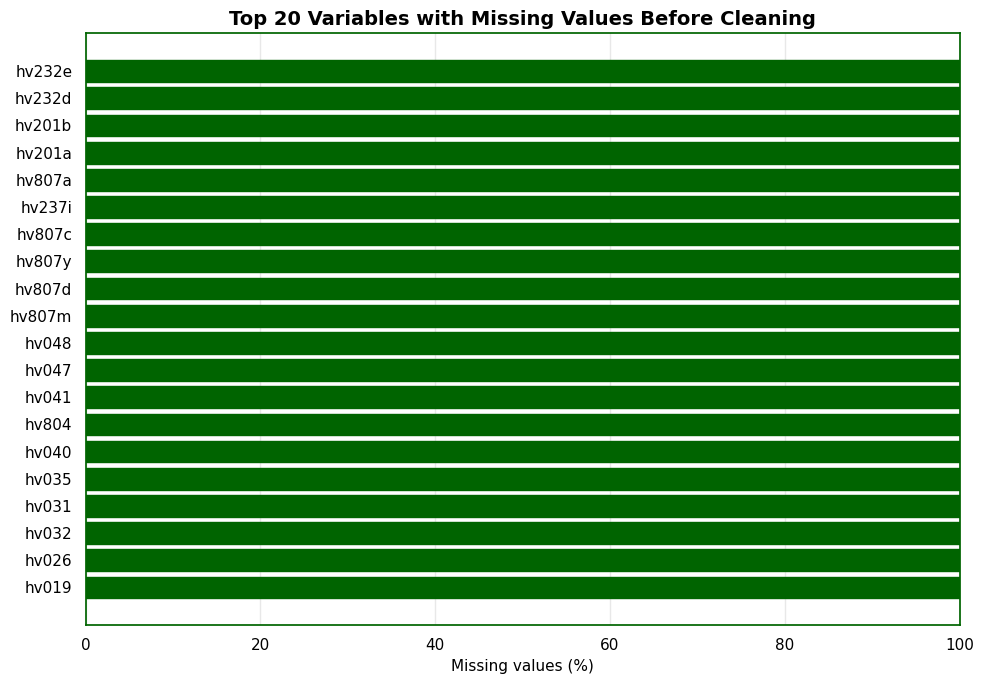

In [ ]:
# Visualize the variables with the highest percentages of missing values before cleaning.

# Plot the 20 columns with the highest ordinary missing percentages
if not missing_before.empty:
    plot_missing = missing_before.head(20).sort_values("Missing percent")
    plt.figure(figsize=(10, 7))
    plt.barh(plot_missing["Variable"], plot_missing["Missing percent"])
    plt.xlabel("Missing values (%)")
    plt.title("Top 20 Variables with Missing Values Before Cleaning")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()
plt.close()

### 11 Review columns with 80% or more missing values

A high missing-value percentage is a reason to investigate a variable, not an automatic reason to delete it. A variable may be important to a research question or may only be asked of a particular group.

We keep high-missingness columns in the cleaned master dataset unless they are completely empty. Later analysis can use a variable-specific subset of valid records, with the amount of missing information reported.

In [ ]:
# List columns with at least 80% missing values before cleaning
high_missing_columns = missing_before[missing_before["Missing percent"] >= 80].copy()

display(high_missing_columns[["Variable", "Description", "Missing count", "Missing percent", "Non-missing count"]])
print("Number of columns with 80% or more missing values:", len(high_missing_columns))

,Variable,Description,Missing count,Missing percent,Non-missing count
22,hv019,na - keyer identification,103719,100.00,0
29,hv026,na - place of residence,103719,100.00,0
34,hv032,na - office editor,103719,100.00,0
33,hv031,na - field editor,103719,100.00,0
35,hv035,na - number of eligible children for height and weight,103719,100.00,0
36,hv040,cluster altitude in meters,103719,100.00,0
49,hv804,na - number of visits for biomarker,103719,100.00,0
37,hv041,na - total adults measured,103719,100.00,0
44,hv047,team number,103719,100.00,0
45,hv048,na - team supervisor,103719,100.00,0


Number of columns with 80% or more missing values: 132


## 12. Investigate important missing value patterns

### SHA registration and SHIF payment

The payment question is not expected to apply to every household member. The existing project interpretation is that current month SHIF payment is assessed for members registered in their own right.

Therefore, missing payment values among dependants and non-registrants must not be filled with unpaid. That would create false lapsed members and inflate the payment gap.

In [ ]:
# Examine how SHA registration and SHIF payment responses relate to each other and to residence status; this helps identify valid skip patterns.

display(pd.crosstab(
    df_raw["hv102"],
    df_raw["sh27"].isna(),
    margins=True
))

display(pd.crosstab(
    df_raw["sh27"].fillna(-1),
    df_raw["sh28"].fillna(-1),
    margins=True
))

own_right_source = df_raw["sh27"] == 1
print("Own-right registrants in source file:", own_right_source.sum())
print(
    "Missing SHIF payment among own-right registrants:",
    df_raw.loc[own_right_source, "sh28"].isna().sum()
)

sh27,False,True,All
hv102,,,
0,0,2399,2399
1,101320,0,101320
All,101320,2399,103719


sh28,-1.0,0.0,1.0,8.0,All
sh27,,,,,
-1.0,2399,0,0,0,2399
0.0,61165,0,0,0,61165
1.0,0,10713,7339,799,18851
2.0,19890,0,0,0,19890
8.0,1414,0,0,0,1414
All,84868,10713,7339,799,103719


Own-right registrants in source file: 18851
Missing SHIF payment among own-right registrants: 0


#### 13. Check missing SHIF payment responses among registration categories

The overall SHIF payment  missing percentage maybe high because this question may not apply to everyone. We compare missing payment responses across SHA registration categories. This helps us understand where payment information is unavailable.

We will not interpret missing payment values as unpaid unless the questionnaire and eligibility rules support that interpretation.

In [ ]:
# Compare missing SHIF payment responses across SHA registration categories
payment_missing_by_registration = df_raw.groupby("sh27", dropna=False)["sh28"].agg(
    Records="size",
    Missing_Payment=lambda values: values.isna().sum()
)
payment_missing_by_registration["Missing Percentage (%)"] = (
    payment_missing_by_registration["Missing_Payment"]
    / payment_missing_by_registration["Records"] * 100
).round(2)

display(payment_missing_by_registration)

,Records,Missing_Payment,Missing Percentage (%)
sh27,,,
0.0,61165,61165,100.0
1.0,18851,0,0.0
2.0,19890,19890,100.0
8.0,1414,1414,100.0
NaN,2399,2399,100.0


### 14. Age variables

The age variables hv105 (household member age) and hv220 (household head age) use code 98 for Don't know in the project documentation.

A value of 98 is not a real age. We will convert it to missing in the cleaned copy and create a flag to show which records originally had an unknown age.

We will not use the median to fill these ages. Median imputation would invent a person's age and could place them in the wrong age group.

In [ ]:
# Check special age codes such as 98 and compare them with residence status so that unknown ages are not mistaken for real ages.

for column in ["hv105", "hv220"]:
    print(
        column,
        "code 98:",
        (df_raw[column] == 98).sum(),
        "| ordinary missing:",
        df_raw[column].isna().sum()
    )

display(pd.crosstab(df_raw["hv102"], df_raw["hv105"] == 98))
display(pd.crosstab(df_raw["hv102"], df_raw["hv220"] == 98))

hv105 code 98: 93 | ordinary missing: 0
hv220 code 98: 166 | ordinary missing: 0


hv105,False,True
hv102,,
0,2395,4
1,101231,89


hv220,False,True
hv102,,
0,2397,2
1,101156,164


### 15. Education variables

Education fields can be missing because the question was not applicable, because of a skip pattern, or because the response was unknown.

The cleaning rules used here are variable-specific:
- hv106 = 8: unknown education level.
- hv107 = 98: unknown completed year. Code 8 is retained because it can be a valid completed-year response.
- hv108 = 97 or 98: inconsistent or unknown.
- hv109 = 8: unknown.
- sheduc and shlevel = 97 or 98: inconsistent or unknown.

We do not fill skipped education responses with zero. A skipped answer is not automatically the same as no education.

In [ ]:
# Investigate education-variable missingness and response codes in relation to the respondent education category before recoding.

for column in ["hv107", "hv108", "hv109", "sheduc", "shlevel"]:
    print("\nMissingness for", column)
    display(pd.crosstab(
        df_raw["hv106"].fillna(-1),
        df_raw[column].isna(),
        margins=True
    ))

for column in ["hv106", "hv107", "hv108", "hv109", "sheduc", "shlevel"]:
    print("\nValues in", column)
    display(df_raw[column].value_counts(dropna=False).sort_index().to_frame("Count"))


Missingness for hv107


hv107,False,True,All
hv106,,,
-1.0,6,13,19
0.0,38,28022,28060
1.0,35868,50,35918
2.0,30398,0,30398
3.0,9016,0,9016
8.0,0,308,308
All,75326,28393,103719



Missingness for hv108


hv108,False,True,All
hv106,,,
-1.0,19,0,19
0.0,7346,20714,28060
1.0,35918,0,35918
2.0,30398,0,30398
3.0,9016,0,9016
8.0,308,0,308
All,83005,20714,103719



Missingness for hv109


hv109,False,All
hv106,,
-1.0,19,19
0.0,28060,28060
1.0,35918,35918
2.0,30398,30398
3.0,9016,9016
8.0,308,308
All,103719,103719


... (12 outputs left out)


Values in sheduc


,Count
sheduc,
0.0,6898
1.0,35880
2.0,7487
3.0,488
4.0,22413
5.0,5822
6.0,3194
7.0,92
8.0,410



Values in shlevel


,Count
shlevel,
0.0,3029
1.0,10196
2.0,14804
3.0,12929
4.0,19238
5.0,3915
6.0,4484
7.0,4641
8.0,9202


### 16. Land and informal-business variables

Land area and business details may only be collected when a household reports ownership or operation. Missing values can therefore be structural.

988 code is identified as an unknown land-area code for hv245 and sh131b, and 8 as an unknown response for sh154b. We will convert only those documented codes to missing and retain flags.

We will not change missing land or business details to zero unless the relevant questionnaire logic confirms that zero is the correct meaning.

In [ ]:
# Check conditional missingness in land, agriculture, and business-related variables to distinguish skipped questions from data errors.

display(pd.crosstab(df_raw["hv244"], df_raw["hv245"].isna(), margins=True))
display(pd.crosstab(df_raw["sh131a"], df_raw["sh131b"].isna(), margins=True))
display(pd.crosstab(df_raw["sh154b"], df_raw["sh154ba"].isna(), margins=True))

for column in ["hv245", "sh131b", "sh154b"]:
    print("\n", column)
    display(df_raw[column].value_counts(dropna=False).sort_index().to_frame("Count"))

hv245,False,True,All
hv244,,,
0,0,55989,55989
1,47730,0,47730
All,47730,55989,103719


sh131b,False,True,All
sh131a,,,
0,0,85440,85440
1,18279,0,18279
All,18279,85440,103719


sh154ba,False,True,All
sh154b,,,
0,0,83988,83988
1,19659,0,19659
8,0,72,72
All,19659,84060,103719



 hv245


,Count
hv245,
0.0,1921
1.0,4410
2.0,8726
3.0,1083
4.0,10404
5.0,617
6.0,1565
7.0,107
8.0,6562



 sh131b


,Count
sh131b,
0.0,4248
1.0,2967
2.0,2571
3.0,115
4.0,2200
5.0,302
6.0,278
7.0,33
8.0,1231



 sh154b


,Count
sh154b,
0,83988
1,19659
8,72


### 17. Other health-insurance variables

The sh30 fields describe insurance types other than SHA. The categories include private medical insurance, community-based insurance, county schemes, employer-managed insurance, other insurance, none, and don't know.

None and Don't know are not interchangeable. The cleaned target will preserve unclear responses rather than automatically classifying them as uninsured.

In [ ]:
# Inspect the response codes for other health-insurance sources before creating insurance-related indicators.

other_insurance_columns = [
    "sh30a", "sh30b", "sh30c", "sh30d", "sh30x", "sh30y", "sh30z"
]

for column in other_insurance_columns:
    print("\n", column, "-", variable_labels.get(column, ""))
    display(df_raw[column].value_counts(dropna=False).sort_index().to_frame("Count"))


 sh30a - type of health insurance other than sha: private medical insurance


,Count
sh30a,
0.0,100463
1.0,857
NaN,2399



 sh30b - type of health insurance other than sha: community based health insurance other 


,Count
sh30b,
0.0,101227
1.0,93
NaN,2399



 sh30c - type of health insurance other than sha: county insurance scheme


,Count
sh30c,
0.0,101141
1.0,179
NaN,2399


... (4 outputs left out)


 sh30y - type of health insurance other than sha: none


,Count
sh30y,
0.0,2590
1.0,98730
NaN,2399



 sh30z - type of health insurance: don't know


,Count
sh30z,
0.0,100441
1.0,879
NaN,2399


## 18. Cleaning decisions and why we make them

| Data issue | Cleaning decision | Why |
|---|---|---|
| Entirely empty columns | Drop from the working dataset | A column with no observed values cannot contribute information |
| Blank text values | Convert blank strings to missing | A blank is not a meaningful response |
| Extra spaces in IDs/text | Strip outer spaces and standardize repeated spaces | Prevents the same ID from appearing in different text formats |
| Visitors | Exclude from the resident analysis copy | The main analysis is about usual household residents |
| Age code 98 | Convert to missing and create a flag | “Don't know” is not a valid age |
| Education special codes | Recode only the documented variable-specific codes | The same numeric code can mean different things in different variables |
| Land-area code 998 | Convert to missing and create a flag | Unknown land size is not zero |
| Business ownership code 8 | Convert to missing and create a flag | Unknown ownership is not “no business” |
| SHA/SHIF code 8 | Convert to missing and create flags | Unknown registration/payment response must not be treated as a definite answer |
| Structural skips | Keep as missing | A skipped question is not necessarily a data error |
| Other remaining missing values | Do not apply blanket imputation | Imputation must be justified for each analysis variable and fitted on training data only |

We do not remove a row simply because one of its columns is missing. Different CareGap questions use different variables, and a record may still be useful even when one field is blank.

High-missingness decision: Columns with 80% or more missing values are retained unless they are completely empty. For example, shif_payment_code is important to the payment-compliance objective, so it is kept and analysed only among eligible registered members with a known response. Land-area columns are optional socioeconomic variables and may be left out of a model if their missingness is too high or their information is not needed.

## 19. Create a working copy and remove completely empty columns

Before dropping empty columns, we also standardize text fields:
- Convert empty or whitespace-only strings to NaN.
- Remove spaces at the beginning and end of text.
- Replace repeated internal whitespace with a single space.

This is important for hhid, which is stored as text with padding spaces. We preserve the identifier as text rather than converting it to a number.

In [ ]:
# Make a working copy, standardize text spacing, convert blank placeholder strings to missing values, and remove columns that are entirely empty.

df_work = df_raw.copy()

# Clean text columns without changing the original source dataframe
text_columns = df_work.select_dtypes(include=["object", "string"]).columns

for column in text_columns:
    df_work[column] = df_work[column].astype("string").str.strip()
    df_work[column] = df_work[column].str.replace(r"\s+", " ", regex=True)

    # Treat blank strings and common text placeholders as missing
    df_work[column] = df_work[column].replace(
        ["", "NA", "N/A", "NULL", "NONE", "NAN", "MISSING"],
        pd.NA
    )

print("Blank text values remaining:")
display(
    df_work.select_dtypes(include=["object", "string"])
    .isna().sum()
    .sort_values(ascending=False)
    .head(15)
)

# Remove columns that are now 100% missing
empty_columns_removed = df_work.columns[df_work.isna().all()].tolist()
df_work = df_work.dropna(axis=1, how="all").copy()

print("Columns removed because they are 100% missing:", len(empty_columns_removed))
print(empty_columns_removed)
print("Shape after removing empty columns:", df_work.shape)

Blank text values remaining:


,0
hml34,103719
hhid,0
hv000,0


Columns removed because they are 100% missing: 104
['hv019', 'hv026', 'hv031', 'hv032', 'hv035', 'hv040', 'hv041', 'hv047', 'hv048', 'hv804', 'hv807d', 'hv807m', 'hv807y', 'hv807c', 'hv807a', 'hv201a', 'hv201b', 'hv232c', 'hv232d', 'hv232e', 'hv234', 'hv234a', 'hv236a', 'hv237', 'hv237a', 'hv237b', 'hv237c', 'hv237d', 'hv237e', 'hv237f', 'hv237g', 'hv237h', 'hv237i', 'hv237j', 'hv237k', 'hv237x', 'hv237z', 'hv239', 'hv246i', 'hv246j', 'hv246k', 'hv253', 'hv253a', 'hv253b', 'hv253c', 'hv253d', 'hv253e', 'hv253f', 'hv253g', 'hv253h', 'hv253x', 'hv253z', 'hv110', 'hv111', 'hv112', 'hv113', 'hv114', 'hv118', 'hv121', 'hv122', 'hv123', 'hv124', 'hv125', 'hv126', 'hv127', 'hv128', 'hv129', 'hml5', 'hml6', 'hml8', 'hml9', 'hmle', 'hml24', 'hml16a', 'hml30', 'hml31', 'hml32', 'hml32a', 'hml32b', 'hml32c', 'hml32d', 'hml32e', 'hml32f', 'hml32g', 'hml33', 'hml34', 'hml35', 'hml36', 'hml37a', 'hml37b', 'hml37c', 'hml37d', 'hml37e', 'hml37f', 'hml37g', 'hml37h', 'hml37i', 'hml37j', 'hml37k', 'hml3

### Why we drop 100% missing columns

A column that is missing in every row contains no information for this survey file. Keeping it adds clutter and makes the later merge more difficult.

We drop only columns that are completely empty after blank strings have also been treated as missing. Columns with 99%, 80%, or even 50% missing values are not automatically dropped. They may still contain important responses, and their missingness may be explained by questionnaire skip patterns.

## 20. Keep usual residents and rename key columns for easier reading

We keep only hv102 = 1 in the working analysis dataset. The source dataframe remains unchanged.

After reviewing the Stata labels, we rename the main project variables to clearer names. We keep the full original-to-new mapping so the team can always trace a friendly name back to its DHS code.

Not every DHS field is renamed: less-used variables keep their official codes to avoid unclear or duplicate names. The full variable dictionary still documents all source columns.

In [ ]:

# Step 1: Check the original residency codes before filtering

print("Original dataset shape:", df_work.shape)

print("\nResidency codes before filtering:")
print(df_work["hv102"].value_counts(dropna=False).sort_index())

usual_residents_count = (df_work["hv102"] == 1).sum()
non_usual_residents_count = (df_work["hv102"] == 0).sum()
missing_residency_count = df_work["hv102"].isna().sum()

print("\nResidency summary:")
print("Usual residents:", usual_residents_count)
print("Non-usual residents:", non_usual_residents_count)
print("Missing residency records:", missing_residency_count)


# Step 2: Retain only usual residents (HV102 = 1)

df_cleaned = df_work.loc[df_work["hv102"] == 1].copy()

# Create a readable residency status column
df_cleaned["residency_status"] = "Usual resident"

print("\nFiltering results:")
print("Records before filtering:", len(df_work))
print("Usual residents retained:", len(df_cleaned))
print("Non-usual residents excluded:", non_usual_residents_count)
print("Records with missing residency excluded:", missing_residency_count)
print("Records removed:", len(df_work) - len(df_cleaned))


# Step 3: Confirm that only usual residents remain

print("\nResidency codes in the filtered dataset:")
print(df_cleaned["hv102"].value_counts(dropna=False))

print("\nResidency status in the filtered dataset:")
print(df_cleaned["residency_status"].value_counts(dropna=False))

assert (df_cleaned["hv102"] == 1).all(), (
    "Filtering check failed: non-usual or missing residency records remain."
)


# Step 4: Define clearer names for the original DHS variables

friendly_names = {
    "hhid": "household_id",
    "hvidx": "member_line_number",
    "hv000": "survey_country_code",
    "hv001": "cluster_id",
    "hv002": "household_number",
    "hv003": "respondent_line_number",
    "hv005": "raw_sample_weight",
    "hv006": "interview_month",
    "hv007": "interview_year",
    "hv008": "interview_date_code",
    "hv009": "household_size",
    "hv021": "primary_sampling_unit",
    "hv022": "sampling_strata",
    "hv023": "sampling_stratification",
    "hv024": "county_code",
    "hv025": "residence_code",
    "hv101": "relationship_to_head",
    "hv102": "usual_resident_code",
    "hv103": "slept_in_household_last_night",
    "hv104": "sex_code",
    "hv105": "age",
    "hv106": "highest_education_level",
    "hv107": "highest_year_education",
    "hv108": "total_years_education",
    "hv109": "educational_attainment",
    "hv219": "household_head_sex",
    "hv220": "household_head_age",
    "hv270": "wealth_quintile",
    "hv271": "wealth_index_score",
    "hv244": "owns_agricultural_land",
    "hv245": "agricultural_land_hectares",
    "sh131a": "owns_nonagricultural_land",
    "sh131b": "nonagricultural_land_hectares",
    "sh154b": "owns_or_operates_informal_business",
    "sh27": "sha_registration_code",
    "sh28": "shif_payment_code",
    "sh30a": "other_insurance_private",
    "sh30b": "other_insurance_community",
    "sh30c": "other_insurance_county_scheme",
    "sh30d": "other_insurance_employer",
    "sh30x": "other_insurance_other",
    "sh30y": "other_insurance_none",
    "sh30z": "other_insurance_dont_know"
}


# Step 5: Rename only variables that are present in the dataset

rename_dictionary = {
    old_name: new_name
    for old_name, new_name in friendly_names.items()
    if old_name in df_cleaned.columns
}

df_cleaned = df_cleaned.rename(columns=rename_dictionary)


# Step 6: Create a summary of the renamed variables

rename_summary = pd.DataFrame({
    "Original DHS code": list(rename_dictionary.keys()),
    "Readable column name": list(rename_dictionary.values()),
    "Meaning": [
        variable_labels.get(old_name, "No label stored")
        for old_name in rename_dictionary.keys()
    ]
})

display(rename_summary)


# Step 7: Perform final checks

print("\nFinal cleaned dataset shape:", df_cleaned.shape)

print(
    "Duplicate column names after renaming:",
    df_cleaned.columns.duplicated().sum()
)

print("\nFinal residency status distribution:")
print(df_cleaned["residency_status"].value_counts(dropna=False))

print(
    "\nRemaining non-usual residents:",
    (df_cleaned["usual_resident_code"] == 0).sum()
)

print(
    "Remaining missing residency records:",
    df_cleaned["usual_resident_code"].isna().sum()
)

print("\nOriginal source dataset shape:", df_work.shape)
print("Final usual-resident dataset shape:", df_cleaned.shape)


Original dataset shape: (103719, 203)

Residency codes before filtering:
hv102
0      2399
1    101320
Name: count, dtype: int64

Residency summary:
Usual residents: 101320
Non-usual residents: 2399
Missing residency records: 0

Filtering results:
Records before filtering: 103719
Usual residents retained: 101320
Non-usual residents excluded: 2399
Records with missing residency excluded: 0
Records removed: 2399

Residency codes in the filtered dataset:
hv102
1    101320
Name: count, dtype: int64

Residency status in the filtered dataset:
residency_status
Usual resident    101320
Name: count, dtype: int64


,Original DHS code,Readable column name,Meaning
0,hhid,household_id,case identification
1,hvidx,member_line_number,line number
2,hv000,survey_country_code,country code and phase
3,hv001,cluster_id,cluster number
4,hv002,household_number,household number
5,hv003,respondent_line_number,respondent's line number (answering household questionnaire)
6,hv005,raw_sample_weight,household sample weight (6 decimals)
7,hv006,interview_month,month of interview
8,hv007,interview_year,year of interview
9,hv008,interview_date_code,date of interview (cmc)



Final cleaned dataset shape: (101320, 204)
Duplicate column names after renaming: 0

Final residency status distribution:
residency_status
Usual resident    101320
Name: count, dtype: int64

Remaining non-usual residents: 0
Remaining missing residency records: 0

Original source dataset shape: (103719, 203)
Final usual-resident dataset shape: (101320, 204)


## 21. Recode documented special values and create flags

We create flags before changing the special values. A flag records that the original response was unknown or inconsistent.

The original DHS-coded values remain available in df_raw. This means we can audit our cleaning decisions later.

We do not replace every occurrence of 8, 98, or 998 across the whole dataset. Each replacement is applied only to the variable for which that special code has been documented.

In [ ]:
# Create flags for documented special or unknown response codes so that these records can be identified during analysis rather than silently treated as valid values.

# Create flags for unknown age responses
df_cleaned["flag_age_dont_know"] = (df_cleaned["age"] == 98).astype(int)
df_cleaned["flag_head_age_dont_know"] = (
    df_cleaned["household_head_age"] == 98
).astype(int)

# Create flags for education special responses
df_cleaned["flag_education_level_dont_know"] = (
    df_cleaned["highest_education_level"] == 8
).astype(int)
df_cleaned["flag_highest_year_dont_know"] = (
    df_cleaned["highest_year_education"] == 98
).astype(int)
df_cleaned["flag_total_education_inconsistent"] = (
    df_cleaned["total_years_education"] == 97
).astype(int)
df_cleaned["flag_total_education_dont_know"] = (
    df_cleaned["total_years_education"] == 98
).astype(int)
df_cleaned["flag_attainment_dont_know"] = (
    df_cleaned["educational_attainment"] == 8
).astype(int)

# Flags for newer education fields that retain their DHS codes
if "sheduc" in df_cleaned.columns:
    df_cleaned["flag_sheduc_special"] = df_cleaned["sheduc"].isin([97, 98]).astype(int)
if "shlevel" in df_cleaned.columns:
    df_cleaned["flag_shlevel_special"] = df_cleaned["shlevel"].isin([97, 98]).astype(int)

# Flags for land area and business ownership
df_cleaned["flag_agricultural_land_unknown"] = (
    df_cleaned["agricultural_land_hectares"] == 998
).astype(int)
df_cleaned["flag_nonagricultural_land_unknown"] = (
    df_cleaned["nonagricultural_land_hectares"] == 998
).astype(int)
df_cleaned["flag_business_ownership_dont_know"] = (
    df_cleaned["owns_or_operates_informal_business"] == 8
).astype(int)

# Flags for SHA registration and SHIF payment
df_cleaned["flag_sha_registration_dont_know"] = (
    df_cleaned["sha_registration_code"] == 8
).astype(int)
df_cleaned["flag_shif_payment_dont_know"] = (
    df_cleaned["shif_payment_code"] == 8
).astype(int)

# Replace special codes with missing values in the working dataset
df_cleaned["age"] = df_cleaned["age"].replace(98, np.nan)
df_cleaned["household_head_age"] = df_cleaned["household_head_age"].replace(98, np.nan)

df_cleaned["highest_education_level"] = (
    df_cleaned["highest_education_level"].replace(8, np.nan)
)
df_cleaned["highest_year_education"] = (
    df_cleaned["highest_year_education"].replace(98, np.nan)
)
df_cleaned["total_years_education"] = (
    df_cleaned["total_years_education"].replace([97, 98], np.nan)
)
df_cleaned["educational_attainment"] = (
    df_cleaned["educational_attainment"].replace(8, np.nan)
)

if "sheduc" in df_cleaned.columns:
    df_cleaned["sheduc"] = df_cleaned["sheduc"].replace([97, 98], np.nan)
if "shlevel" in df_cleaned.columns:
    df_cleaned["shlevel"] = df_cleaned["shlevel"].replace([97, 98], np.nan)

df_cleaned["agricultural_land_hectares"] = (
    df_cleaned["agricultural_land_hectares"].replace(998, np.nan)
)
df_cleaned["nonagricultural_land_hectares"] = (
    df_cleaned["nonagricultural_land_hectares"].replace(998, np.nan)
)
df_cleaned["owns_or_operates_informal_business"] = (
    df_cleaned["owns_or_operates_informal_business"].replace(8, np.nan)
)
df_cleaned["sha_registration_code"] = (
    df_cleaned["sha_registration_code"].replace(8, np.nan)
)
df_cleaned["shif_payment_code"] = (
    df_cleaned["shif_payment_code"].replace(8, np.nan)
)

# Review the number of records affected by each special code
flag_columns = [col for col in df_cleaned.columns if col.startswith("flag_")]
flag_summary = df_cleaned[flag_columns].sum().sort_values(ascending=False).to_frame(
    "Records affected"
)
display(flag_summary)

,Records affected
flag_sha_registration_dont_know,1414
flag_shif_payment_dont_know,799
flag_agricultural_land_unknown,756
flag_total_education_dont_know,423
flag_nonagricultural_land_unknown,341
flag_attainment_dont_know,314
flag_sheduc_special,314
flag_education_level_dont_know,301
flag_shlevel_special,172
flag_head_age_dont_know,164


## 22. Create CareGap insurance indicators

###  SHA registration

Working response interpretation used in this notebook:
- 0 = not registered.
- 1 = registered in own right.
- 2 = registered as a dependant.
- 8 = don't know (converted to missing above).

We create a readable category and a binary registration indicator. Dependants count as registered for the broad SHA registration indicator.

### 13.2 Current-month SHIF payment

The working interpretation in the existing project notebook is:
- 0 = not paid.
- 1 = paid.
- 8 = don't know.

The lapsed-payment indicator is created only for people registered in their own right and with a known payment response. Dependants and non-registrants are not labelled unpaid.



In [ ]:
# Convert the original SHA registration and SHIF payment codes into readable categories and carefully defined analysis indicators.

registration_labels = {
    0: "Not registered",
    1: "Registered in own right",
    2: "Registered as a dependant"
}

df_cleaned["sha_status"] = df_cleaned["sha_registration_code"].map(
    registration_labels
)
df_cleaned["sha_registered"] = df_cleaned["sha_registration_code"].map({
    0: 0,
    1: 1,
    2: 1
})

df_cleaned["shif_status"] = df_cleaned["shif_payment_code"].map({
    0: "Unpaid",
    1: "Paid"
})

df_cleaned["shif_lapsed"] = (
    df_cleaned["shif_payment_code"].map({0: 1, 1: 0})
    .where(df_cleaned["sha_registration_code"] == 1)
)

display(df_cleaned[[
    "sha_registration_code", "sha_status", "sha_registered",
    "shif_payment_code", "shif_status", "shif_lapsed"
]].head(10))

,sha_registration_code,sha_status,sha_registered,shif_payment_code,shif_status,shif_lapsed
0,1.0,Registered in own right,1.0,0.0,Unpaid,1.0
1,1.0,Registered in own right,1.0,0.0,Unpaid,1.0
2,1.0,Registered in own right,1.0,0.0,Unpaid,1.0
3,2.0,Registered as a dependant,1.0,NaN,NaN,NaN
4,0.0,Not registered,0.0,NaN,NaN,NaN
5,1.0,Registered in own right,1.0,0.0,Unpaid,1.0
6,NaN,NaN,NaN,NaN,NaN,NaN
7,1.0,Registered in own right,1.0,0.0,Unpaid,1.0
8,1.0,Registered in own right,1.0,1.0,Paid,0.0
9,1.0,Registered in own right,1.0,1.0,Paid,0.0


### 23. Other insurance and a cautious overall insurance indicator

The other-insurance fields are separate response items. We treat an affirmative response in any listed non-SHA insurance type as evidence of other insurance.

We keep none and don't know separate. If the responses do not provide enough evidence to say a person is insured or uninsured, the derived indicator stays missing.



In [ ]:
# Here we creates or updates part of the dataset needed for the CareGap Kenya data-understanding and cleaning workflow.

other_insurance_yes_columns = [
    "other_insurance_private",
    "other_insurance_community",
    "other_insurance_county_scheme",
    "other_insurance_employer",
    "other_insurance_other"
]

df_cleaned["other_insurance_any"] = (
    df_cleaned[other_insurance_yes_columns].eq(1).any(axis=1).astype(int)
)

df_cleaned["other_insurance_dont_know"] = (
    df_cleaned["other_insurance_dont_know"] == 1
).astype(int)

df_cleaned["other_insurance_none_reported"] = (
    df_cleaned["other_insurance_none"] == 1
).astype(int)

confirmed_insurance = (
    df_cleaned["sha_registration_code"].isin([1, 2])
    | (df_cleaned["other_insurance_any"] == 1)
)

no_insurance_reported = (
    df_cleaned["sha_registration_code"].eq(0)
    & (df_cleaned["other_insurance_none_reported"] == 1)
)

df_cleaned["insured_any"] = np.where(
    confirmed_insurance, 1,
    np.where(no_insurance_reported, 0, np.nan)
)

df_cleaned["uninsured"] = np.where(
    no_insurance_reported, 1,
    np.where(confirmed_insurance, 0, np.nan)
)

df_cleaned["insurance_unclear"] = (
    df_cleaned["insured_any"].isna()
).astype(int)

display(df_cleaned[[
    "sha_status", "other_insurance_any",
    "other_insurance_none_reported", "other_insurance_dont_know",
    "insured_any", "uninsured", "insurance_unclear"
]].head(12))

print("Known insured/uninsured records:")
display(df_cleaned["insured_any"].value_counts(dropna=False).to_frame("Records"))

,sha_status,other_insurance_any,other_insurance_none_reported,other_insurance_dont_know,insured_any,uninsured,insurance_unclear
0,Registered in own right,0,1,0,1.0,0.0,0
1,Registered in own right,0,1,0,1.0,0.0,0
2,Registered in own right,0,1,0,1.0,0.0,0
3,Registered as a dependant,0,1,0,1.0,0.0,0
4,Not registered,0,1,0,0.0,1.0,0
5,Registered in own right,0,1,0,1.0,0.0,0
6,NaN,0,1,0,NaN,NaN,1
7,Registered in own right,1,0,0,1.0,0.0,0
8,Registered in own right,0,1,0,1.0,0.0,0
9,Registered in own right,0,1,0,1.0,0.0,0


Known insured/uninsured records:


,Records
insured_any,
0.0,60566
1.0,39329
NaN,1425


## 24. Create readable county, residence, sex and age-group columns

The county code hv024 is mapped to the 47 Kenyan counties. We retain the numeric county_code and add a readable county column.

We also add readable residence and sex categories. Age groups follow the 0 - 14, 15 - 24, 25 - 59 and 60+ grouping used in the specific objectives.

In [ ]:
# This cell creates or updates part of the dataset needed for the CareGap Kenya data-understanding and cleaning workflow.

county_names = {
    1: "Mombasa", 2: "Kwale", 3: "Kilifi", 4: "Tana River", 5: "Lamu",
    6: "Taita Taveta", 7: "Garissa", 8: "Wajir", 9: "Mandera", 10: "Marsabit",
    11: "Isiolo", 12: "Meru", 13: "Tharaka-Nithi", 14: "Embu", 15: "Kitui",
    16: "Machakos", 17: "Makueni", 18: "Nyandarua", 19: "Nyeri", 20: "Kirinyaga",
    21: "Murang'a", 22: "Kiambu", 23: "Turkana", 24: "West Pokot", 25: "Samburu",
    26: "Trans Nzoia", 27: "Uasin Gishu", 28: "Elgeyo-Marakwet", 29: "Nandi",
    30: "Baringo", 31: "Laikipia", 32: "Nakuru", 33: "Narok", 34: "Kajiado",
    35: "Kericho", 36: "Bomet", 37: "Kakamega", 38: "Vihiga", 39: "Bungoma",
    40: "Busia", 41: "Siaya", 42: "Kisumu", 43: "Homa Bay", 44: "Migori",
    45: "Kisii", 46: "Nyamira", 47: "Nairobi"
}

df_cleaned["county"] = df_cleaned["county_code"].map(county_names)
df_cleaned["residence"] = df_cleaned["residence_code"].map({
    1: "Urban", 2: "Rural"
})
df_cleaned["sex"] = df_cleaned["sex_code"].map({
    1: "Male", 2: "Female"
})

df_cleaned["age_group"] = pd.cut(
    df_cleaned["age"],
    bins=[-1, 14, 24, 59, 120],
    labels=["0-14", "15-24", "25-59", "60+"]
)

print("Counties represented:", df_cleaned["county"].nunique())
print("Missing county labels:", df_cleaned["county"].isna().sum())
print("County names not matched:", sorted(
    df_cleaned.loc[df_cleaned["county"].isna(), "county_code"].dropna().unique()
))
display(df_cleaned[["county_code", "county", "residence", "sex", "age", "age_group"]].head())

Counties represented: 47
Missing county labels: 0
County names not matched: []


,county_code,county,residence,sex,age,age_group
0,1,Mombasa,Urban,Female,28.0,25-59
1,1,Mombasa,Urban,Female,NaN,NaN
2,1,Mombasa,Urban,Female,22.0,15-24
3,1,Mombasa,Urban,Male,0.0,0-14
4,1,Mombasa,Urban,Male,21.0,15-24


## 25. Prepare survey weights and design variables

The household-member sample weight is hv005, renamed to raw_sample_weight. DHS weights are commonly stored with six implied decimal places, so we divide by 1,000,000 to create weight.

We retain the primary sampling unit and strata fields. For official estimates and standard errors, the team must account for the survey design (weights, clusters and strata), not just use ordinary unweighted percentages.

In [ ]:
# This cell creates or updates part of the dataset needed for the CareGap Kenya data-understanding and cleaning workflow.
df_cleaned["weight"] = df_cleaned["raw_sample_weight"] / 1_000_000

design_columns = [
    "weight", "raw_sample_weight", "cluster_id",
    "primary_sampling_unit", "sampling_strata"
]
display(df_cleaned[design_columns].describe(include="all"))

print("Missing analysis weights:", df_cleaned["weight"].isna().sum())
print("Missing cluster IDs:", df_cleaned["cluster_id"].isna().sum())
print("Missing strata:", df_cleaned["sampling_strata"].isna().sum())

,weight,raw_sample_weight,cluster_id,primary_sampling_unit,sampling_strata
count,101320.000000,1.013200e+05,101320.000000,101320.000000,101320.000000
mean,0.917351,9.173510e+05,490.059159,490.059159,47.062841
std,0.972228,9.722275e+05,293.046804,293.046804,27.743634
min,0.044718,4.471800e+04,1.000000,1.000000,1.000000
25%,0.416252,4.162520e+05,206.000000,206.000000,21.000000
50%,0.762352,7.623520e+05,500.500000,500.500000,47.000000
75%,1.057451,1.057451e+06,749.000000,749.000000,72.000000
max,8.139455,8.139455e+06,1000.000000,1000.000000,92.000000


Missing analysis weights: 0
Missing cluster IDs: 0
Missing strata: 0


## 26. Visual data understanding

The charts help us understand the people represented in this file and the distribution of important project variables.

These first charts show unweighted sample counts.

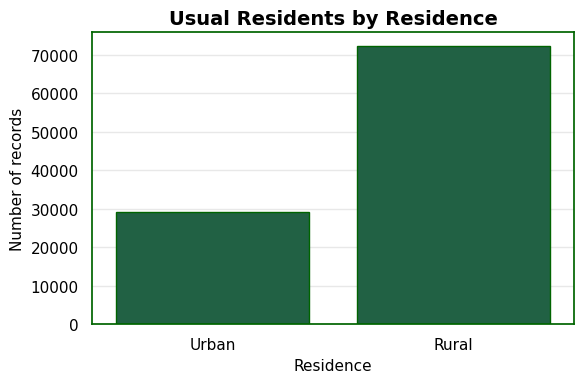

In [ ]:
# Create and display demographic visualizations that describe the cleaned usual-resident sample.

# 16.1 Residents by urban/rural residence
plt.figure(figsize=(6, 4))
sns.countplot(data=df_cleaned, x="residence", order=["Urban", "Rural"], color="#176B45")
plt.title("Usual Residents by Residence")
plt.xlabel("Residence")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
plt.close()



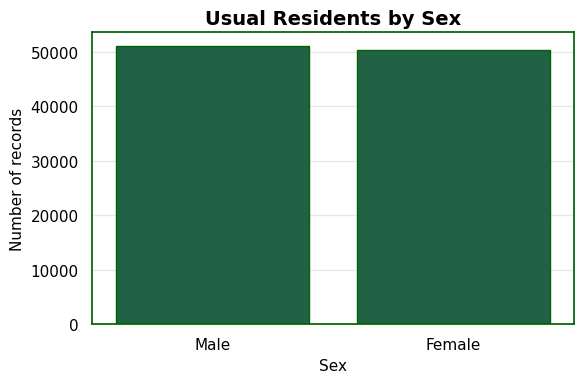

In [ ]:
# 16.2 Residents by sex
plt.figure(figsize=(6, 4))
sns.countplot(data=df_cleaned, x="sex", order=["Male", "Female"], color="#176B45")
plt.title("Usual Residents by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
plt.close()

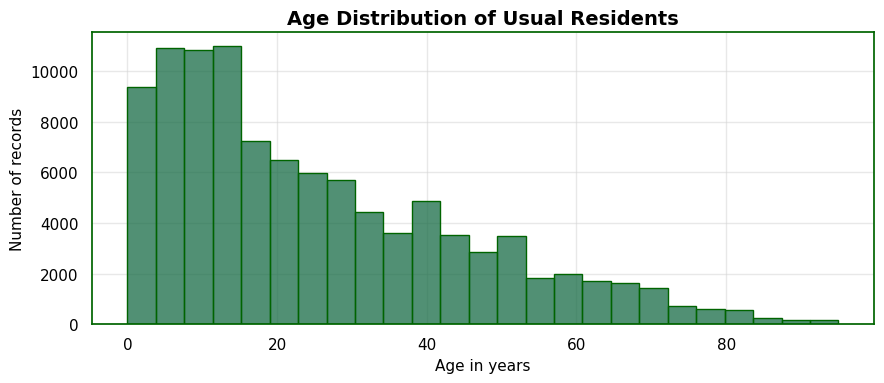

In [ ]:
# 16.3 Age distribution
plt.figure(figsize=(9, 4))
sns.histplot(data=df_cleaned, x="age", bins=25, kde=False, color="#176B45")
plt.title("Age Distribution of Usual Residents")
plt.xlabel("Age in years")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
plt.close()


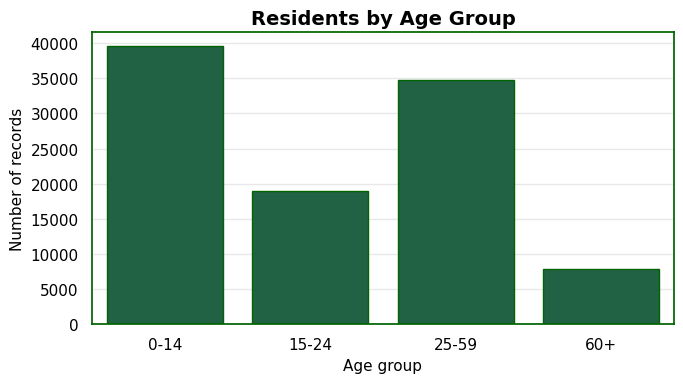

In [ ]:
# 16.4 Age groups
plt.figure(figsize=(7, 4))
sns.countplot(
    data=df_cleaned, x="age_group",
    order=["0-14", "15-24", "25-59", "60+"], color="#176B45"
)
plt.title("Residents by Age Group")
plt.xlabel("Age group")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
plt.close()

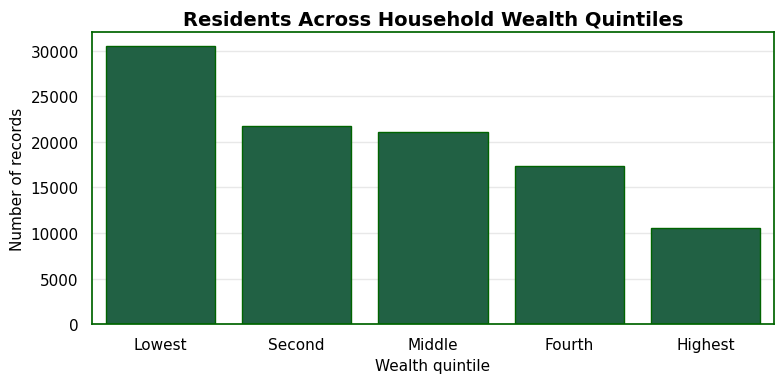

In [ ]:
# Summarized wealth-quintile representation and visualize the number of resident records sampled in each county.

# 16.5 Residents across wealth quintiles
wealth_labels = {
    1: "Lowest", 2: "Second", 3: "Middle",
    4: "Fourth", 5: "Highest"
}
df_cleaned["wealth_group"] = df_cleaned["wealth_quintile"].map(wealth_labels)

plt.figure(figsize=(8, 4))
sns.countplot(
    data=df_cleaned, x="wealth_group",
    order=["Lowest", "Second", "Middle", "Fourth", "Highest"], color="#176B45"
)
plt.title("Residents Across Household Wealth Quintiles")
plt.xlabel("Wealth quintile")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
plt.close()



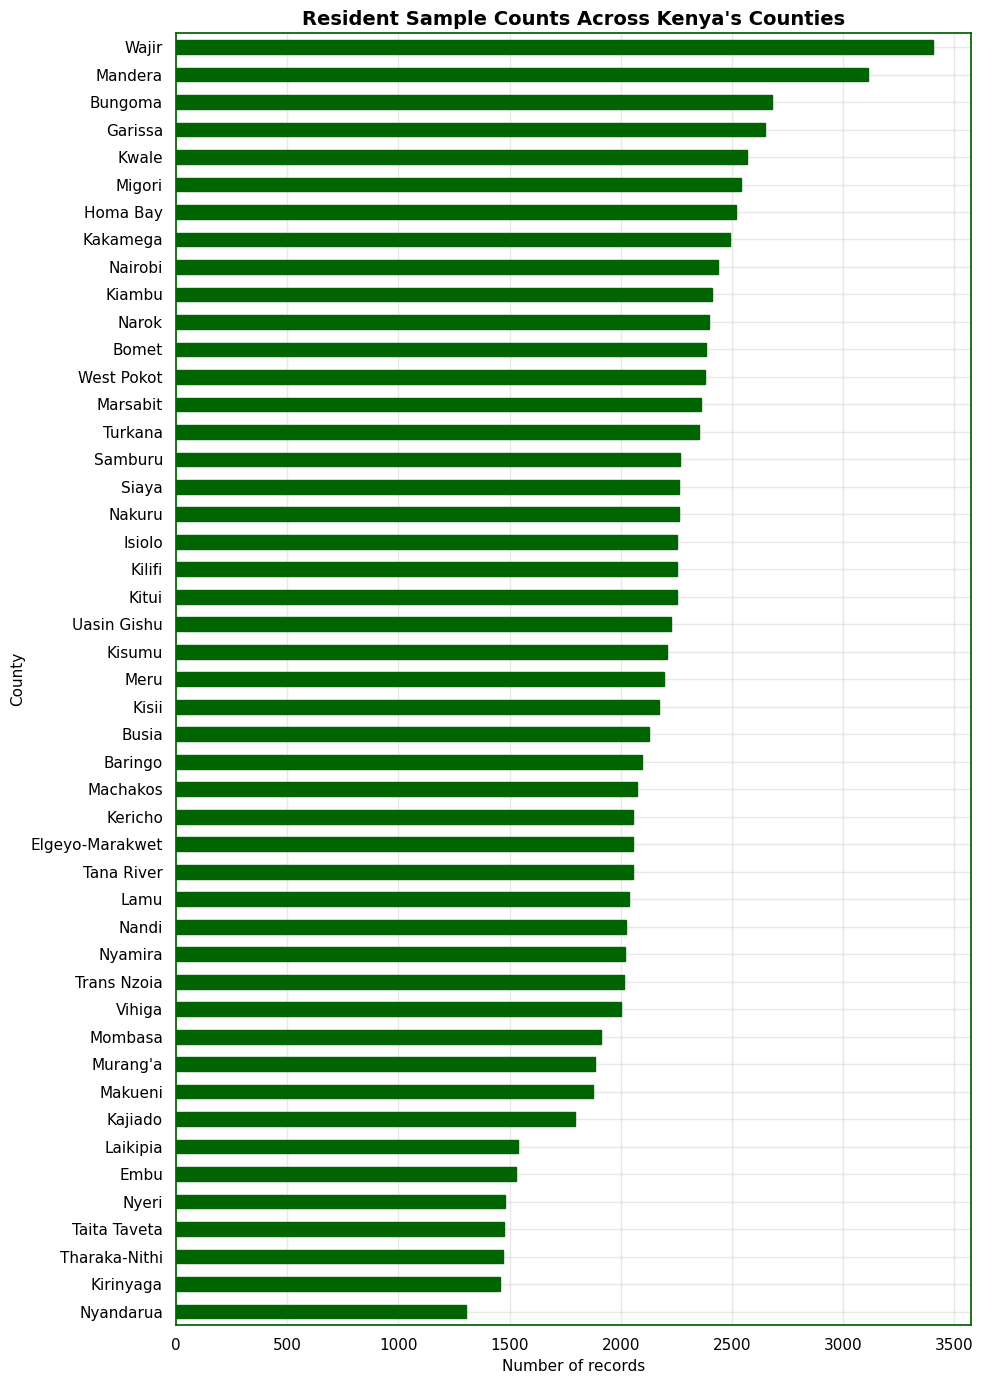

In [ ]:
# 16.6 Number of resident records in each county
county_counts = df_cleaned["county"].value_counts().sort_values()
plt.figure(figsize=(10, 14))
county_counts.plot(kind="barh")
plt.title("Resident Sample Counts Across Kenya's Counties")
plt.xlabel("Number of records")
plt.ylabel("County")
plt.tight_layout()
plt.show()
plt.close()

### 27. SHA registration and SHIF payment patterns

The SHA registration chart includes the three known categories. The SHIF payment chart is restricted to people registered in their own right and with a known payment response.

This avoids treating a dependant or a non-registrant as a person who failed to pay their own monthly premium.

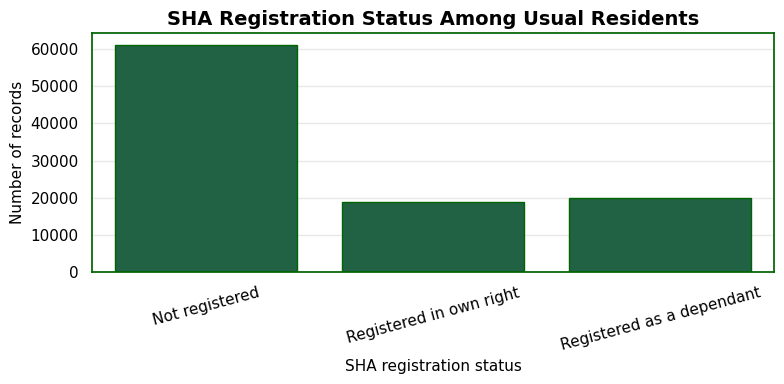

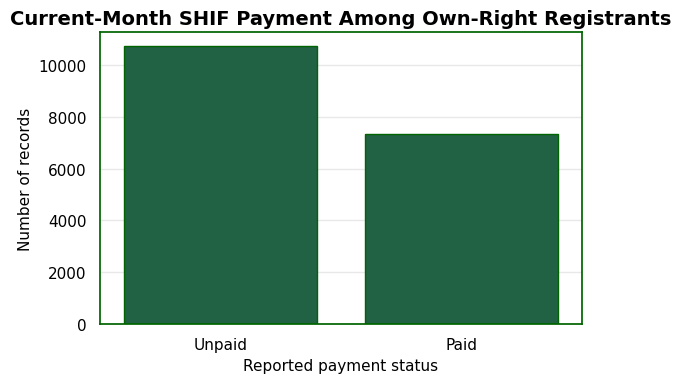

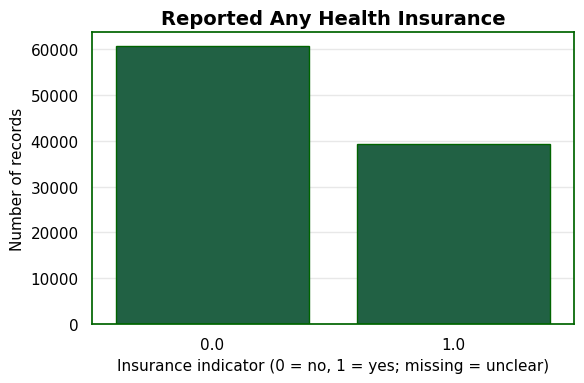

In [ ]:
# Visualize SHA registration categories and current-month SHIF payment among eligible own-right registrants with known payment responses.

plt.figure(figsize=(8, 4))
sns.countplot(
    data=df_cleaned,
    x="sha_status",
    order=[
        "Not registered",
        "Registered in own right",
        "Registered as a dependant"
    ], color="#176B45"
)
plt.title("SHA Registration Status Among Usual Residents")
plt.xlabel("SHA registration status")
plt.ylabel("Number of records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
plt.close()

own_right_known_payment = df_cleaned[
    (df_cleaned["sha_registration_code"] == 1)
    & (df_cleaned["shif_status"].notna())
]

plt.figure(figsize=(6, 4))
sns.countplot(
    data=own_right_known_payment,
    x="shif_status",
    order=["Unpaid", "Paid"], color="#176B45"
)
plt.title("Current-Month SHIF Payment Among Own-Right Registrants")
plt.xlabel("Reported payment status")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(6, 4))
sns.countplot(data=df_cleaned, x="insured_any", color="#176B45")
plt.title("Reported Any Health Insurance")
plt.xlabel("Insurance indicator (0 = no, 1 = yes; missing = unclear)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
plt.close()

### 28. Education distribution

Education is useful for understanding socioeconomic differences in insurance exclusion. The chart shows the coded highest education level after the documented Don't know code has been changed to missing.

The code meanings are retained in the Stata variable dictionary.

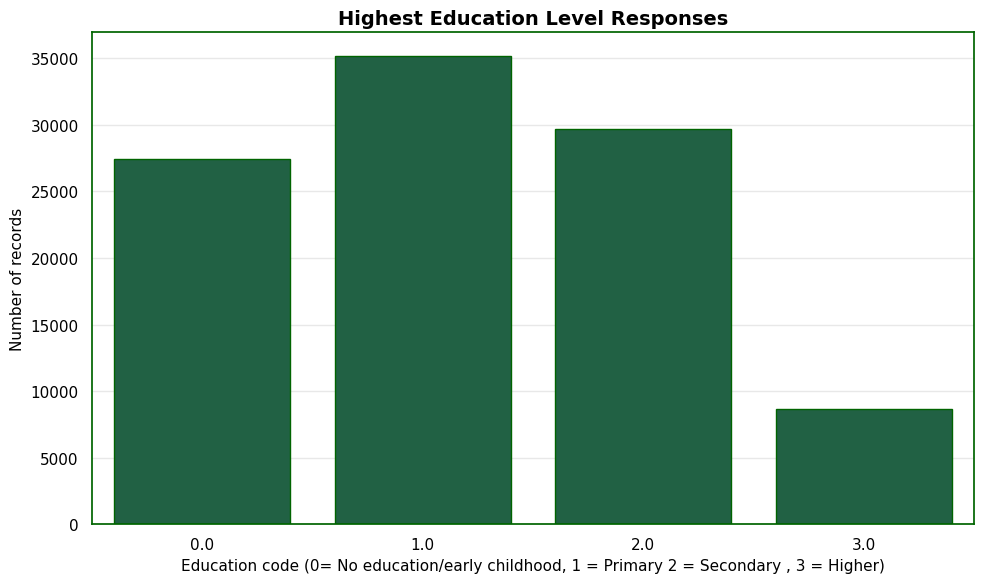

In [ ]:
# Visualize education responses to understand the education profile and identify categories requiring careful interpretation.

plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_cleaned,
    x="highest_education_level",
    order=sorted(df_cleaned["highest_education_level"].dropna().unique()), color="#176B45"
)
plt.title("Highest Education Level Responses")
plt.xlabel('Education code (0= No education/early childhood, 1 = Primary 2 = Secondary , 3 = Higher)')
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
plt.close()

## 29. County-level SHA registration patterns

The following charts are exploratory county comparisons. The first chart shows counts; the second shows within-county percentages. They are not population estimates because they are unweighted.

For the CareGap dashboard, we will use weighted county estimates and account for the DHS survey design, we will also consider Small county sample sizes.

In [ ]:
# Check the actual SHA registration categories available in the dataset.

print("SHA status categories:")
print(df_cleaned["sha_status"].value_counts(dropna=False))

print("\nCounty registration cross-tabulation:")
print(pd.crosstab(df_cleaned["county"], df_cleaned["sha_status"]))

SHA status categories:
sha_status
Not registered               61165
Registered as a dependant    19890
Registered in own right      18851
NaN                           1414
Name: count, dtype: int64

County registration cross-tabulation:
sha_status       Not registered  Registered as a dependant  \
county                                                       
Baringo                    1193                        461   
Bomet                      1045                        787   
Bungoma                    1750                        454   
Busia                      1312                        399   
Elgeyo-Marakwet             695                        806   
Embu                        715                        336   
Garissa                    2072                        341   
Homa Bay                   1448                        624   
Isiolo                     1910                        200   
Kajiado                     898                        470   
Kakamega         

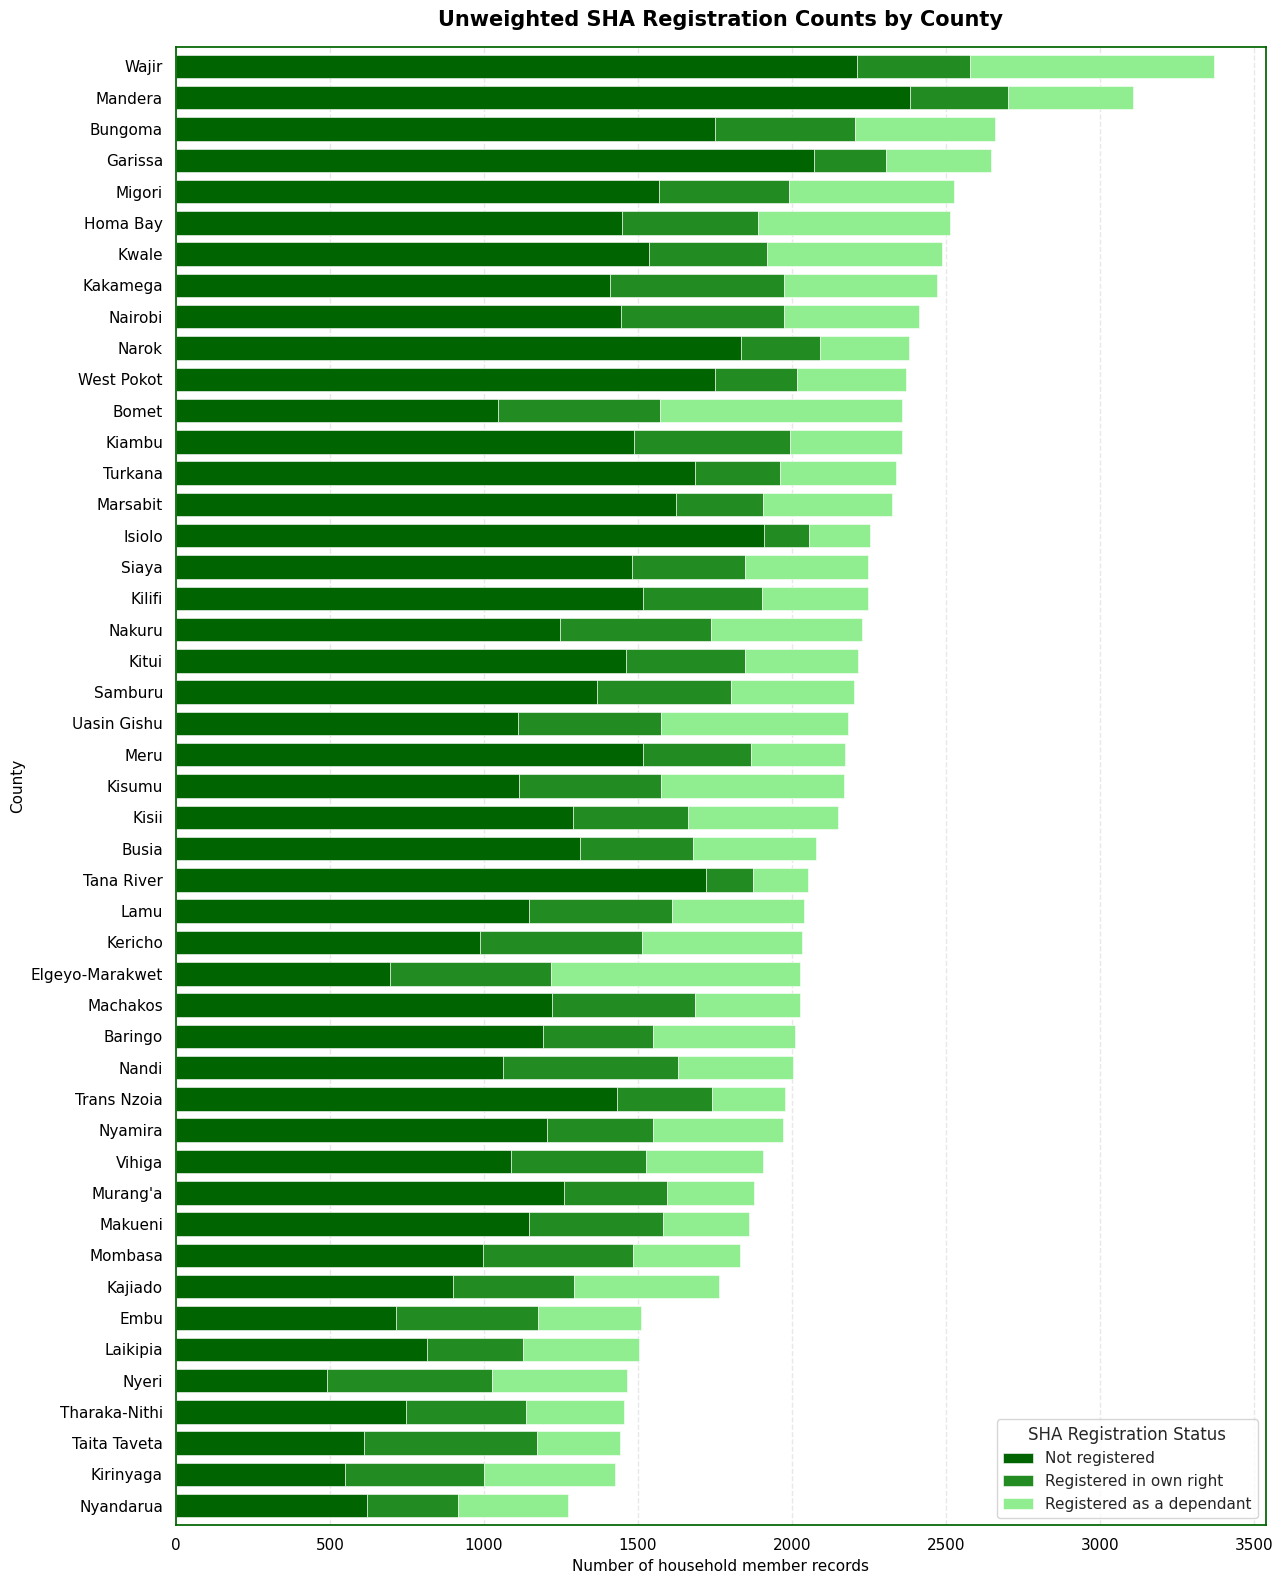

In [ ]:
# Compare unweighted SHA registration counts across counties using a stacked horizontal bar chart.

# Create a cross-tabulation of counties and SHA registration categories.
county_registration_counts = pd.crosstab(
    df_cleaned["county"],
    df_cleaned["sha_status"]
)

# Arrange the three registration categories in the correct order.
registration_order = [
    "Not registered",
    "Registered in own right",
    "Registered as a dependant"
]

county_registration_counts = county_registration_counts[
    registration_order
]

# Sort counties by total number of records.
county_registration_counts = county_registration_counts.loc[
    county_registration_counts.sum(axis=1).sort_values().index
]

# Define three complementary green shades for the SHA categories.
registration_colors = [
    "#006400",  # Dark green: Not registered
    "#228B22",  # Forest green: Registered in own right
    "#90EE90"   # Light green: Registered as a dependant
]

# Create the stacked horizontal bar chart.
fig, ax = plt.subplots(figsize=(13, 16))

county_registration_counts.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.75,
    color=registration_colors,
    edgecolor="white",
    linewidth=0.4
)

# Add chart title and axis labels.
ax.set_title(
    "Unweighted SHA Registration Counts by County",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of household member records")
ax.set_ylabel("County")

# Display the SHA registration categories in the legend.
ax.legend(
    title="SHA Registration Status",
    labels=registration_order,
    loc="lower right",
    frameon=True
)

# Maintain the notebook's grid appearance.
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
plt.close()

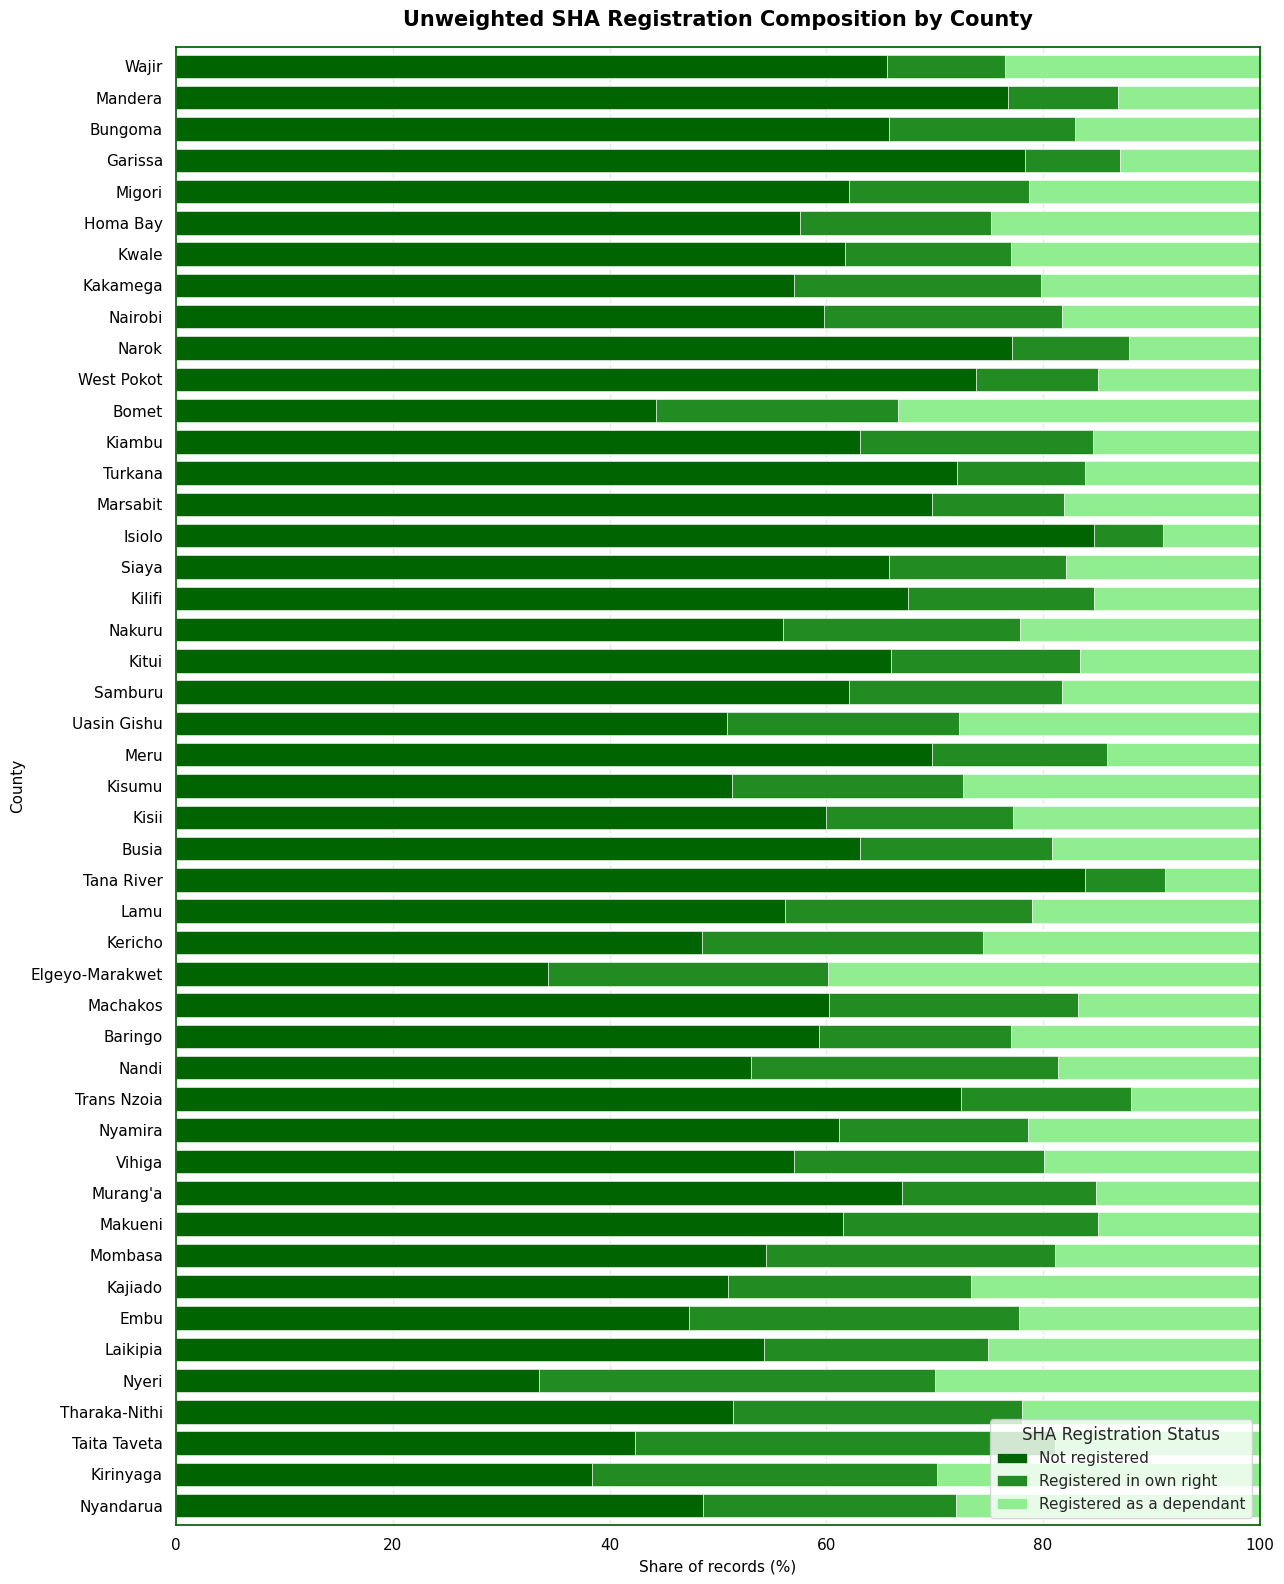

In [ ]:
# Convert county registration counts into within-county percentages and visualize registration composition.

# Calculate the percentage of each SHA registration category within each county.
county_registration_percent = (
    county_registration_counts
    .div(county_registration_counts.sum(axis=1), axis=0)
    * 100
)

# Define the three green shades to maintain a consistent notebook theme.
registration_colors = [
    "#006400",  # Dark green: Not registered
    "#228B22",  # Forest green: Registered in own right
    "#90EE90"   # Light green: Registered as a dependant
]

# Create a 100% stacked horizontal bar chart.
fig, ax = plt.subplots(figsize=(13, 16))

county_registration_percent.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.75,
    color=registration_colors,
    edgecolor="white",
    linewidth=0.4
)

# Add chart title and axis labels.
ax.set_title(
    "Unweighted SHA Registration Composition by County",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Share of records (%)")
ax.set_ylabel("County")

# Set the horizontal axis from 0% to 100%.
ax.set_xlim(0, 100)

# Display the SHA registration categories in the legend.
ax.legend(
    title="SHA Registration Status",
    labels=[
        "Not registered",
        "Registered in own right",
        "Registered as a dependant"
    ],
    loc="lower right",
    frameon=True
)

# Maintain the notebook's grid appearance.
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
plt.close()

## 30. Final missing-value report

We do not expect every cell to be complete. Some missing values are caused by survey skip patterns, some are unknown responses, and some are genuine non-response.

The purpose of this report is to show exactly what remains missing after the documented cleaning decisions.



In [ ]:
# Create the after-cleaning missing-value report, preserving the original DHS variable meanings where possible and identifying derived variables.

reverse_rename = {
    new_name: old_name
    for old_name, new_name in rename_dictionary.items()
}

missing_after = pd.DataFrame({
    "Variable": df_cleaned.columns,
    "Meaning": [
        variable_labels.get(
            reverse_rename.get(column, column),
            "Derived or renamed variable"
        )
        for column in df_cleaned.columns
    ],
    "Data type": df_cleaned.dtypes.astype(str).values,
    "Missing count": df_cleaned.isna().sum().values,
    "Non-missing count": df_cleaned.notna().sum().values,
    "Missing percent": (df_cleaned.isna().mean().values * 100).round(2)
})

missing_after = missing_after.sort_values(
    "Missing percent", ascending=False
)

display(missing_after[missing_after["Missing count"] > 0])
print("Total missing cells:", int(df_cleaned.isna().sum().sum()))
print("Columns with at least one missing value:",
      int((df_cleaned.isna().sum() > 0).sum()))

,Variable,Meaning,Data type,Missing count,Non-missing count,Missing percent
182,hml15,net designation number (hmlidx) for 3rd net person slept under last night,float64,101308,12,99.99
192,sh145e4,business operator 4,float64,101300,20,99.98
191,sh154e3,business operator 3,float64,101240,80,99.92
181,hml14,net designation number (hmlidx) for 2nd net person slept under last night,float64,101020,300,99.70
190,sh154e2,business operator 2,float64,100475,845,99.17
175,hmld,line number of person who slept in this net,float64,98466,2854,97.18
41,hv202,source of non-drinking water,float64,97964,3356,96.69
97,hv257,where septic tanked emptied to,float64,97695,3625,96.42
96,hv256,septic tank emptied by a service provider,float64,97695,3625,96.42
193,sh154f,main economic activity of enterprise,float64,96032,5288,94.78


Total missing cells: 4250651
Columns with at least one missing value: 75


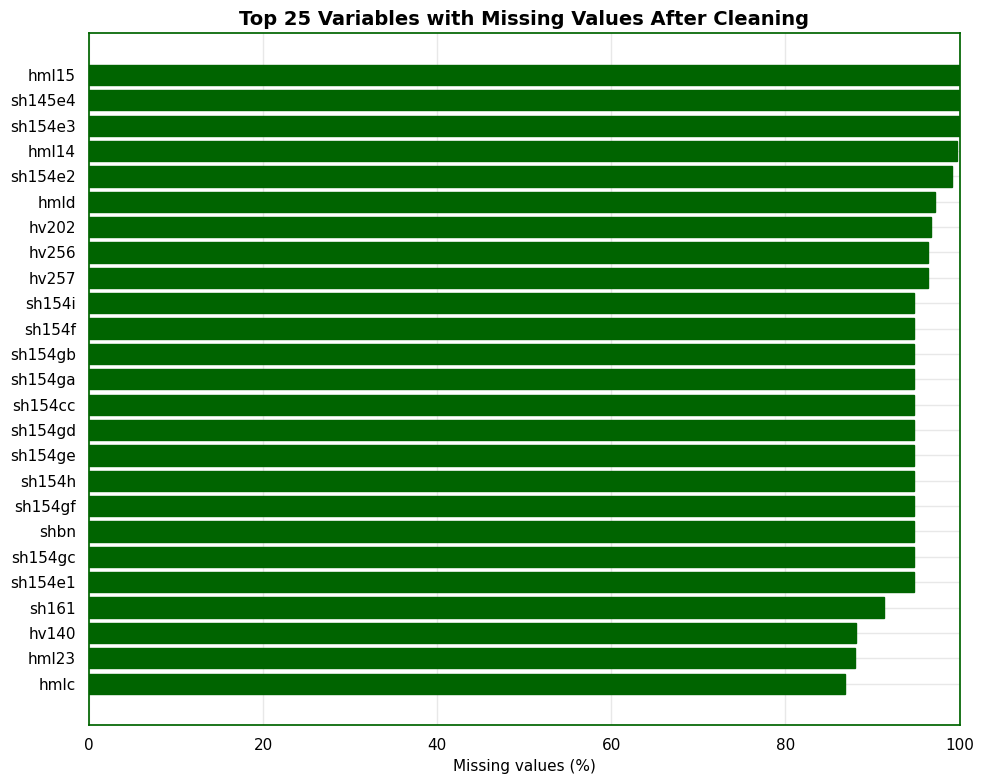

In [ ]:
# Visualize the variables that still contain the highest percentages of missing values after cleaning.

missing_plot = missing_after[
    missing_after["Missing count"] > 0
].head(25).sort_values("Missing percent")

if not missing_plot.empty:
    plt.figure(figsize=(10, 8))
    plt.barh(missing_plot["Variable"], missing_plot["Missing percent"])
    plt.xlabel("Missing values (%)")
    plt.title("Top 25 Variables with Missing Values After Cleaning")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()
plt.close()

## 31. Check text formatting, numeric values and column names

We check for:
- Remaining blank text values.
- Leading/trailing spaces.
- Duplicate column names.
- Infinite numeric values.
- Completely empty columns.

We will not remove punctuation or signs from numeric data automatically. A negative value may be meaningful for some variables (for example, a standardized wealth score). Any unusual numeric value must be checked against the variable definition before changing it.

In [ ]:
# Check whether text columns still contain blank strings or extra spaces, and inspect duplicate column names and infinite numeric values.

# Check blank strings and leading/trailing spaces in text columns
text_columns = df_cleaned.select_dtypes(include=["object", "string"]).columns
text_quality = []

for column in text_columns:
    values = df_cleaned[column].dropna().astype(str)
    text_quality.append({
        "Variable": column,
        "Blank strings": (values.str.strip() == "").sum(),
        "Leading/trailing spaces": (
            values.str.match(r"^\s|\s$").sum()
        ),
        "Unique text values": values.nunique()
    })

display(pd.DataFrame(text_quality))

# Check duplicate column names
print("Duplicate column names:", df_cleaned.columns.duplicated().sum())

# Check infinite values in numeric columns
numeric_columns = df_cleaned.select_dtypes(include=[np.number]).columns
infinite_counts = pd.Series({
    column: np.isinf(df_cleaned[column]).sum()
    for column in numeric_columns
})
print("Total infinite numeric values:", int(infinite_counts.sum()))

# Review negative numeric values without automatically changing them
negative_counts = pd.Series({
    column: (df_cleaned[column] < 0).sum()
    for column in numeric_columns
})
display(
    negative_counts[negative_counts > 0]
    .sort_values(ascending=False)
    .to_frame("Negative values to review")
)

,Variable,Blank strings,Leading/trailing spaces,Unique text values
0,household_id,0,0,26380
1,survey_country_code,0,0,1
2,residency_status,0,0,1
3,sha_status,0,0,3
4,shif_status,0,0,2
5,county,0,0,47
6,residence,0,0,2
7,sex,0,0,2
8,wealth_group,0,0,5


Duplicate column names: 0
Total infinite numeric values: 0


,Negative values to review
wealth_index_score,57181
hv271a,53121


## 32. Validate cleaning decisions and derived targets

This section checks that special codes documented above no longer remain in their cleaned columns, and that the SHIF lapse target is only assigned to own-right registrants with a known payment response.

The checks are designed to catch mistakes before the data are saved or merged with the other DHS files.

In [ ]:
# Check whether documented special response codes remain and verify that the SHIF lapse indicator is only assigned to eligible own-right registrants.

special_code_checks = {
    "age": [98],
    "household_head_age": [98],
    "highest_education_level": [8],
    "highest_year_education": [98],
    "total_years_education": [97, 98],
    "educational_attainment": [8],
    "agricultural_land_hectares": [998],
    "nonagricultural_land_hectares": [998],
    "owns_or_operates_informal_business": [8],
    "sha_registration_code": [8],
    "shif_payment_code": [8]
}

special_code_results = {}
for column, codes in special_code_checks.items():
    special_code_results[column] = int(df_cleaned[column].isin(codes).sum())

display(pd.Series(
    special_code_results,
    name="Special codes remaining"
).to_frame())

# Check that shif_lapsed is only assigned to own-right registrants
invalid_lapse_rows = df_cleaned[
    df_cleaned["shif_lapsed"].notna()
    & (
        (df_cleaned["sha_registration_code"] != 1)
        | (df_cleaned["shif_payment_code"].isna())
    )
]

print("Invalid SHIF lapse assignments:", len(invalid_lapse_rows))

# Check target values
print("SHIF lapse values:")
display(df_cleaned["shif_lapsed"].value_counts(dropna=False).to_frame("Records"))

,Special codes remaining
age,0
household_head_age,0
highest_education_level,0
highest_year_education,0
total_years_education,0
educational_attainment,0
agricultural_land_hectares,0
nonagricultural_land_hectares,0
owns_or_operates_informal_business,0
sha_registration_code,0


Invalid SHIF lapse assignments: 0
SHIF lapse values:


,Records
shif_lapsed,
NaN,83268
1.0,10713
0.0,7339


## 33. Final dataset quality checks

A dataset can be cleaned and still contain missing values. We therefore define cleaned as:
- Empty columns removed.
- Blank text fields handled.
- Key identifiers formatted consistently.
- Duplicate household-member keys checked.
- Documented special response codes recoded.
- County and survey-weight fields checked.
- Derived targets created without assigning false values to inapplicable records.
- Remaining missing values reported and explained.

The final status below is based on these checks. It does not mean every variable is complete or that the file is ready for every model without further feature-specific preparation.

In [ ]:
# final structural quality checks for duplicate records, duplicate member keys, empty columns, text formatting, and required project fields.

# Duplicate record and key checks
duplicate_full_rows = int(df_cleaned.duplicated().sum())
duplicate_member_keys = int(
    df_cleaned.duplicated(
        subset=["household_id", "member_line_number"]
    ).sum()
)

# Empty columns and text formatting checks
all_empty_columns = int(df_cleaned.isna().all().sum())
duplicate_column_names = int(df_cleaned.columns.duplicated().sum())

text_columns = df_cleaned.select_dtypes(include=["object", "string"]).columns
remaining_blank_text = 0
for column in text_columns:
    remaining_blank_text += int(
        (df_cleaned[column].dropna().astype(str).str.strip() == "").sum()
    )

# Required project fields
missing_county = int(df_cleaned["county"].isna().sum())
missing_weight = int(df_cleaned["weight"].isna().sum())
missing_cluster = int(df_cleaned["cluster_id"].isna().sum())
missing_strata = int(df_cleaned["sampling_strata"].isna().sum())

# Special codes remaining
special_codes_remaining = sum(special_code_results.values())

quality_checks = pd.DataFrame({
    "Check": [
        "Completely duplicated rows",
        "Duplicate household-member keys",
        "Completely empty columns",
        "Duplicate column names",
        "Blank text values",
        "Missing county labels",
        "Missing survey weights",
        "Missing cluster IDs",
        "Missing sampling strata",
        "Documented special codes remaining"
    ],
    "Result": [
        duplicate_full_rows,
        duplicate_member_keys,
        all_empty_columns,
        duplicate_column_names,
        remaining_blank_text,
        missing_county,
        missing_weight,
        missing_cluster,
        missing_strata,
        special_codes_remaining
    ]
})

display(quality_checks)

# These conditions define whether the core cleaning checks passed
core_checks_passed = (
    duplicate_full_rows == 0
    and duplicate_member_keys == 0
    and all_empty_columns == 0
    and duplicate_column_names == 0
    and remaining_blank_text == 0
    and missing_county == 0
    and missing_weight == 0
    and special_codes_remaining == 0
)

if core_checks_passed:
    print("CLEANING STATUS: PASSED — all defined core cleaning checks passed.")
else:
    print("CLEANING STATUS: REVIEW REQUIRED — at least one core check needs attention.")

print("Final cleaned resident dataset shape:", df_cleaned.shape)
print("Residents retained:", len(df_cleaned))
print("Counties represented:", df_cleaned["county"].nunique())
print("Remaining missing cells:", int(df_cleaned.isna().sum().sum()))

,Check,Result
0,Completely duplicated rows,0
1,Duplicate household-member keys,0
2,Completely empty columns,0
3,Duplicate column names,0
4,Blank text values,0
5,Missing county labels,0
6,Missing survey weights,0
7,Missing cluster IDs,0
8,Missing sampling strata,0
9,Documented special codes remaining,0


CLEANING STATUS: PASSED — all defined core cleaning checks passed.
Final cleaned resident dataset shape: (101320, 233)
Residents retained: 101320
Counties represented: 47
Remaining missing cells: 4250651


In [ ]:
# Check the completeness of important CareGap variables after cleaning
important_cleaned_names = [rename_dictionary.get(code, code) for code in important_codes]
important_cleaned_names = [col for col in important_cleaned_names if col in df_cleaned.columns]
missing_important_names = [rename_dictionary.get(code, code) for code in important_codes if rename_dictionary.get(code, code) not in df_cleaned.columns]

important_quality_report = pd.DataFrame({
    "Cleaned Variable": important_cleaned_names,
    "Data Type": [df_cleaned[col].dtype for col in important_cleaned_names],
    "Missing Values": [df_cleaned[col].isna().sum() for col in important_cleaned_names],
    "Missing Percentage (%)": [(df_cleaned[col].isna().mean() * 100).round(2) for col in important_cleaned_names],
    "Available Values": [df_cleaned[col].notna().sum() for col in important_cleaned_names],
    "Unique Values": [df_cleaned[col].nunique(dropna=True) for col in important_cleaned_names]
}).sort_values("Missing Percentage (%)", ascending=False)

display(important_quality_report)
print("Important variables missing from cleaned dataset:", missing_important_names)

,Cleaned Variable,Data Type,Missing Values,Missing Percentage (%),Available Values,Unique Values
24,nonagricultural_land_hectares,float64,83752,82.66,17568,75
27,shif_payment_code,float64,83268,82.18,18052,2
22,agricultural_land_hectares,float64,55641,54.92,45679,83
14,highest_year_education,float64,27874,27.51,73446,12
15,total_years_education,float64,20801,20.53,80519,26
26,sha_registration_code,float64,1414,1.40,99906,3
13,highest_education_level,float64,319,0.31,101001,4
16,educational_attainment,float64,314,0.31,101006,6
18,household_head_age,float64,164,0.16,101156,81
12,age,float64,89,0.09,101231,96


Important variables missing from cleaned dataset: []


In [ ]:
# Display the renamed versions of the important variables.

# Create a renamed_variables table from the existing rename_summary.
renamed_variables = rename_summary.rename(columns={
    "Original DHS code": "Original DHS Variable",
    "Readable column name": "Cleaned Variable Name"
})

# Convert important variable codes to lowercase to match the DHS column names.
important_codes_lower = [code.lower() for code in important_codes]

# Filter the table to show only important variables.
important_renamed = renamed_variables[
    renamed_variables["Original DHS Variable"].isin(important_codes_lower)
].reset_index(drop=True)

# Display the results.
display(important_renamed)

print("Important variables renamed:", len(important_renamed))

,Original DHS Variable,Cleaned Variable Name,Meaning
0,hhid,household_id,case identification
1,hvidx,member_line_number,line number
2,hv001,cluster_id,cluster number
3,hv005,raw_sample_weight,household sample weight (6 decimals)
4,hv009,household_size,number of household members
5,hv021,primary_sampling_unit,primary sampling unit
6,hv022,sampling_strata,sample strata for sampling errors
7,hv023,sampling_stratification,stratification used in sample design
8,hv024,county_code,region
9,hv025,residence_code,type of place of residence


Important variables renamed: 35


In [ ]:
# Detailed checks for important variables: missingness, negative values, and infinite values
important_cleaned_names = [rename_dictionary.get(code, code) for code in important_codes]
important_cleaned_names = [col for col in important_cleaned_names if col in df_cleaned.columns]

important_detailed_report = pd.DataFrame({
    "Cleaned Variable": important_cleaned_names,
    "Data Type": [df_cleaned[col].dtype for col in important_cleaned_names],
    "Missing Values": [df_cleaned[col].isna().sum() for col in important_cleaned_names],
    "Missing Percentage (%)": [(df_cleaned[col].isna().mean() * 100).round(2) for col in important_cleaned_names],
    "Unique Values": [df_cleaned[col].nunique(dropna=True) for col in important_cleaned_names],
    "Negative Values": [(df_cleaned[col] < 0).sum() if pd.api.types.is_numeric_dtype(df_cleaned[col]) else 0 for col in important_cleaned_names],
    "Infinite Values": [np.isinf(df_cleaned[col]).sum() if pd.api.types.is_numeric_dtype(df_cleaned[col]) else 0 for col in important_cleaned_names]
})

display(important_detailed_report)

,Cleaned Variable,Data Type,Missing Values,Missing Percentage (%),Unique Values,Negative Values,Infinite Values
0,household_id,string[python],0,0.00,26380,0,0
1,member_line_number,int8,0,0.00,21,0,0
2,cluster_id,int16,0,0.00,998,0,0
3,raw_sample_weight,int32,0,0.00,991,0,0
4,primary_sampling_unit,int16,0,0.00,998,0,0
5,sampling_strata,int8,0,0.00,92,0,0
6,sampling_stratification,int8,0,0.00,92,0,0
7,household_size,int8,0,0.00,20,0,0
8,usual_resident_code,int8,0,0.00,1,0,0
9,county_code,int8,0,0.00,47,0,0


In [ ]:
# Calculate total missing values across the 35 important variables

total_missing = df_cleaned[important_cleaned_names].isna().sum().sum()

total_cells = df_cleaned[important_cleaned_names].size

total_missing_percentage = (total_missing / total_cells) * 100

print("\nTOTAL MISSING VALUES")
print("-" * 45)
print("Total missing cells:", total_missing)
print("Total cells checked:", total_cells)
print("Overall missing percentage:", round(total_missing_percentage, 2), "%")

if total_missing == 0:
    print("All 35 important variables have no missing values.")
else:
    print("Missing values still exist in the selected important variables.")


TOTAL MISSING VALUES
---------------------------------------------
Total missing cells: 273708
Total cells checked: 3546200
Overall missing percentage: 7.72 %
Missing values still exist in the selected important variables.


## 34. Save the complete cleaned dataset and supporting reports

We save the full cleaned resident dataset in both CSV and Excel formats. CSV is convenient for Python and merging. Excel is useful for reviewing the complete dataset and its supporting reports.

The Excel workbook contains separate sheets for the cleaned data, missing values, variable dictionary, final quality checks, and important-variable completeness. The dataset has more than 100,000 rows but remains within Excel's row limit.



In [ ]:
# Save the complete cleaned dataset and supporting reports to a private Google Drive folder
output_folder = "/content/drive/MyDrive/CareGap_cleaned_outputs"
os.makedirs(output_folder, exist_ok=True)

cleaned_csv = os.path.join(output_folder, "KEPR91_cleaned_residents.csv")
excel_file = os.path.join(output_folder, "KEPR91_cleaned_residents_complete.xlsx")
missing_report_file = os.path.join(output_folder, "KEPR91_missing_values_after_cleaning.csv")
dictionary_file = os.path.join(output_folder, "KEPR91_variable_dictionary.csv")
quality_file = os.path.join(output_folder, "KEPR91_cleaning_quality_checks.csv")


# Save the full cleaned data and separate CSV audit reports
df_cleaned.to_csv(cleaned_csv, index=False)
missing_after.to_csv(missing_report_file, index=False)
variable_dictionary.to_csv(dictionary_file, index=False)
quality_checks.to_csv(quality_file, index=False)


# Save all key tables in one Excel workbook for easier review and merging
with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:
    df_cleaned.to_excel(writer, sheet_name="Cleaned_Data", index=False)
    missing_after.to_excel(writer, sheet_name="Missing_Values", index=False)
    variable_dictionary.to_excel(writer, sheet_name="Variable_Dictionary", index=False)
    quality_checks.to_excel(writer, sheet_name="Quality_Checks", index=False)
    important_quality_report.to_excel(writer, sheet_name="Important_Variables", index=False)

print("Saved complete cleaned dataset and reports:")
print(cleaned_csv)
print(excel_file)
print(missing_report_file)
print(dictionary_file)
print(quality_file)

Saved complete cleaned dataset and reports:
/content/drive/MyDrive/CareGap_cleaned_outputs/KEPR91_cleaned_residents.csv
/content/drive/MyDrive/CareGap_cleaned_outputs/KEPR91_cleaned_residents_complete.xlsx
/content/drive/MyDrive/CareGap_cleaned_outputs/KEPR91_missing_values_after_cleaning.csv
/content/drive/MyDrive/CareGap_cleaned_outputs/KEPR91_variable_dictionary.csv
/content/drive/MyDrive/CareGap_cleaned_outputs/KEPR91_cleaning_quality_checks.csv


In [ ]:
# Download the complete cleaned Excel workbook and CSV dataset from Google Colab
from google.colab import files

files.download(excel_file)
files.download(cleaned_csv)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 35. Summary and next steps for CareGap Kenya

### What this dataset contributes
- Household member demographics: sex, age and age groups.
- Geography: all 47 county codes and county names.
- Residence: urban/rural.
- Socioeconomic context: household wealth and education.
- SHA registration and current-month SHIF payment responses.
- Other health-insurance responses.
- Household identifiers, survey weights, clusters and strata.




### Missing values and readiness for analysis

The cleaned dataset is not expected to have zero missing values. Important variables are retained where they support CareGap research questions. During analysis, each metric will use its appropriate valid denominator and missing responses will be reported. For modelling, missing predictor values will be handled inside the training pipeline, while unknown target values will not be imputed.